In [3]:
import json
import pathlib
from pprint import pprint

import h5py
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from matplotlib import colormaps as plt_colormaps
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from scipy.spatial.distance import squareform

sc.set_figure_params(figsize=(5, 5))

In [4]:
# import relevant modules and functions
from bonsai_loop.bonsai_lib import (
    Layout_Tree,
    bonsai_clustering,
    get_bonsai_euclidean_distances,
    get_pdists_on_tree,
    get_pdists_on_tree_euclidean,
)
from bonsai_loop.shared import sample_farthest_points

# Download data

The `data/` folder is hosted on Zenodo — DOI [10.5281/zenodo.19654111](https://doi.org/10.5281/zenodo.19654111). The cell below downloads and extracts it if `./data/` is not already present.

In [3]:
import tarfile
import urllib.request
from pathlib import Path

data_dir = Path("./data")
tarball = Path("2026-04-19-PGC-DE-convergence.tar.gz")
url = f"https://zenodo.org/records/19654111/files/{tarball.name}"

if data_dir.exists():
    print(f"{data_dir} already exists; skipping download.")
else:
    print(f"Downloading {url} ...")
    urllib.request.urlretrieve(url, tarball)
    print(f"Extracting {tarball} ...")
    with tarfile.open(tarball) as tar:
        tar.extractall(".")
    tarball.unlink()
    print(f"Extracted to {data_dir.resolve()}")

data already exists; skipping download.


In [4]:
import inspect

print(inspect.getsource(get_bonsai_euclidean_distances))
print(inspect.getsource(get_pdists_on_tree_euclidean))
print(inspect.getsource(get_pdists_on_tree))
pprint(Layout_Tree.__dict__)

def get_bonsai_euclidean_distances(final_bonsai_folder, cell_ids):
    bonsai_ltqs_gc, _ = get_bonsai_posteriors(final_bonsai_folder, vert_ids=cell_ids)
    num_dims = bonsai_ltqs_gc.shape[0]
    bonsai_dists = distance.pdist(bonsai_ltqs_gc.T, metric='sqeuclidean') / num_dims
    return bonsai_dists

def get_pdists_on_tree_euclidean(
    nwk_file,
    bonsai_output_folder,
    cell_ids,
    *,
    tree=None,
) -> np.ndarray:
    """
    Pairwise tree-path distances with squared-Euclidean edge weights.

    Edge weights match the parent-child term used elsewhere in bonsai-loop:
    mean((ltqs_parent - ltqs_child)^2). Only tree edges are evaluated (not an
    all-node pdist matrix).

    Parameters
    ----------
    nwk_file
        Path to tree.nwk (used when ``tree`` is not provided).
    bonsai_output_folder
        Bonsai output folder with posterior_ltqs_vertByGene.npy (used when
        ltqsAIRoot is not on tree nodes).
    cell_ids
        Node ids to include in the distance matr

# Toy example

In [ ]:
bonsai_toy_path = pathlib.Path("./data/Bonsai_toy")
toy_bonsai_output_folder = (
    bonsai_toy_path / "bonsai" / "final_bonsai_zscore1.0_tmpStartpremerged_cs_tree/"
)

tab10 = plt_colormaps["tab10"]
with h5py.File(bonsai_toy_path / "bonsai/bonsai_vis_data.hdf", "r") as f:
    metadata = json.loads(f.attrs["metadata_json"])
toy_cell_ids = metadata["cellIds"]
print(toy_cell_ids[:5])

## Compute distances

In [ ]:
# calculated pairwise distances
# straight-line squared euclidean distances
toy_euclidean_distances_straight = squareform(
    get_bonsai_euclidean_distances(
        final_bonsai_folder=toy_bonsai_output_folder,
        cell_ids=toy_cell_ids,
    )
)
# tree distance
toy_tree_distances = squareform(
    get_pdists_on_tree(
        nwk_file=toy_bonsai_output_folder / "tree.nwk",
        cell_ids=toy_cell_ids,
    )
)
# squared euclidean distances based on tree path
toy_euclidean_distances_tree = squareform(
    get_pdists_on_tree_euclidean(
        nwk_file=toy_bonsai_output_folder / "tree.nwk",
        bonsai_output_folder=toy_bonsai_output_folder,
        cell_ids=toy_cell_ids,
    )
)

In [ ]:
# check distributions
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].hist(squareform(toy_tree_distances), bins=100, color="C0")
axes[0].set_title("Tree distance")
axes[1].hist(
    squareform(toy_euclidean_distances_tree),
    bins=100,
    color="C1",
)
axes[1].set_title("Euclidean distance (tree path)")
axes[2].hist(
    squareform(toy_euclidean_distances_straight),
    bins=100,
    color="C2",
)
axes[2].set_title("Euclidean distance (straight line)")
for i, dists in enumerate(
    [toy_tree_distances, toy_euclidean_distances_tree, toy_euclidean_distances_straight]
):
    axes[3].hist(
        squareform(dists),
        bins=100,
        color=f"C{i}",
        alpha=0.5,
        density=True,
    )

for i, ax in enumerate(axes):
    ax.set_xlabel("Distance")
    ax.set_ylabel("Count") if i < 3 else ax.set_ylabel("Density")
    ax.grid(False)

plt.tight_layout()
plt.show()
plt.close()

In [ ]:
# The distance distrbutions still differ a lot, do quantile based matching to match the scales
lo_pct, up_pct = 0.05, 0.95
toy_tree_distances_quantiles = np.quantile(
    squareform(toy_tree_distances), [lo_pct, up_pct]
)
toy_euclidean_distances_straight_quantiles = np.quantile(
    squareform(toy_euclidean_distances_straight), [lo_pct, up_pct]
)
toy_euclidean_distances_tree_quantiles = np.quantile(
    squareform(toy_euclidean_distances_tree), [lo_pct, up_pct]
)
# stretch euclidean distances to tree distance range
toy_euclidean_distances_straight_match = squareform(
    np.maximum(
        (
            squareform(toy_euclidean_distances_straight)
            - toy_euclidean_distances_straight_quantiles[0]
        )
        / (
            toy_euclidean_distances_straight_quantiles[1]
            - toy_euclidean_distances_straight_quantiles[0]
        )
        * (toy_tree_distances_quantiles[1] - toy_tree_distances_quantiles[0])
        + toy_tree_distances_quantiles[0],
        0,
    )
)
toy_euclidean_distances_tree_match = squareform(
    np.maximum(
        (
            squareform(toy_euclidean_distances_tree)
            - toy_euclidean_distances_tree_quantiles[0]
        )
        / (
            toy_euclidean_distances_tree_quantiles[1]
            - toy_euclidean_distances_tree_quantiles[0]
        )
        * (toy_tree_distances_quantiles[1] - toy_tree_distances_quantiles[0])
        + toy_tree_distances_quantiles[0],
        0,
    )
)

In [ ]:
# check distributions again
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].hist(squareform(toy_tree_distances), bins=100, color="C0")
axes[0].set_title("Tree distance")
axes[1].hist(
    squareform(toy_euclidean_distances_tree_match),
    bins=100,
    color="C1",
)
axes[1].set_title("Euclidean distance (tree path)")
axes[2].hist(
    squareform(toy_euclidean_distances_straight_match),
    bins=100,
    color="C2",
)
axes[2].set_title("Euclidean distance (straight line)")
for i, dists in enumerate(
    [
        toy_tree_distances,
        toy_euclidean_distances_tree_match,
        toy_euclidean_distances_straight_match,
    ]
):
    axes[3].hist(
        squareform(dists),
        bins=100,
        color=f"C{i}",
        alpha=0.5,
        density=True,
    )

for i, ax in enumerate(axes):
    ax.set_xlabel("Distance")
    ax.set_ylabel("Count") if i < 3 else ax.set_ylabel("Density")
    ax.grid(False)

plt.tight_layout()
plt.show()
plt.close()

## Compute cell order

In [ ]:
toy_node_id_to_vert_ind = {}
with open(toy_bonsai_output_folder / "vertInfo.txt") as f:
    next(f)
    for line in f:
        parts = line.strip().split("\t")
        toy_node_id_to_vert_ind[parts[2]] = int(parts[0])

toy_G = nx.Graph()
with open(toy_bonsai_output_folder / "edgeInfo.txt") as f:
    for line in f:
        v1, v2, d = line.strip().split("\t")
        toy_G.add_edge(int(v1), int(v2), weight=np.sqrt(float(d)))

print(toy_cell_ids[:5])
pprint(dict(list(toy_node_id_to_vert_ind.items())[:15]))
print(toy_G)

In [ ]:
with h5py.File(bonsai_toy_path / "bonsai/bonsai_vis_data.hdf", "r") as f:
    metadata = json.loads(f.attrs["metadata_json"])
toy_cell_ids = metadata["cellIds"]
# cell ids look like Cell0000000000, take first 3 digits as the cell type
toy_cell_type_vec = np.array([cid[4:7] for cid in toy_cell_ids])
toy_clusters = np.unique(toy_cell_type_vec)
# compute per-cell distance to root and mean cluster distance to root
cell_vert_inds = [toy_node_id_to_vert_ind[cid] for cid in toy_cell_ids]
toy_root_id = "internal_2"
toy__tree_t = nx.shortest_path_length(
    toy_G, source=toy_node_id_to_vert_ind[toy_root_id], weight="weight"
)
toy_dists_to_root = np.array([toy__tree_t[cvid] for cvid in cell_vert_inds])
toy_dists_to_root_by_cluster = np.zeros(len(toy_cell_ids))

for c in toy_clusters:
    toy_dists_to_root_by_cluster[toy_cell_type_vec == c] = np.mean(
        toy_dists_to_root[toy_cell_type_vec == c]
    )
# ordering: by mean cluster distance to root, then by per-cell distance to root
toy_reorder_ind = np.lexsort((toy_dists_to_root, toy_dists_to_root_by_cluster))

In [ ]:
# reorder cells
toy_dist_matrix_tree_t_ordered = toy_tree_distances[toy_reorder_ind, :][
    :, toy_reorder_ind
]
toy_dist_matrix_tree_e_ordered = toy_euclidean_distances_tree_match[toy_reorder_ind, :][
    :, toy_reorder_ind
]
toy_dist_matrix_straight_ordered = toy_euclidean_distances_straight_match[
    toy_reorder_ind, :
][:, toy_reorder_ind]

## Compute cell identity

In [ ]:
toy_window_size = 15
toy_cell_types = toy_clusters
# cell types: 000, 001, 010, 011, 100, 101, 110, 111
toy_colors = tab10.colors
toy_cell_composition_matrix = np.zeros((len(toy_cell_types) + 1, len(toy_cell_ids)))
for i, cell_type in enumerate(toy_cell_types):
    res = np.convolve(
        toy_cell_type_vec[toy_reorder_ind] == cell_type,
        np.ones(toy_window_size),
        mode="valid",
    )
    margin = int(np.ceil((toy_cell_composition_matrix.shape[1] - res.shape[0]) / 2))
    res = np.pad(res, (margin, margin), mode="constant")
    toy_cell_composition_matrix[i, :] = res[: toy_cell_composition_matrix.shape[1]]
toy_cell_composition_matrix[-1, :] = 1
toy_cell_composition_matrix = toy_cell_composition_matrix / np.sum(
    toy_cell_composition_matrix, axis=0
)

## Check tree

In [ ]:
f = h5py.File(bonsai_toy_path / "bonsai/bonsai_vis_data.hdf", "r")
toy_categories = toy_clusters
toy_cat_to_color = dict(zip(toy_clusters, toy_colors[: len(toy_clusters)]))
toy_cell_colors = [toy_cat_to_color[c] for c in toy_cell_type_vec]

toy_coords_d = f["layout_coords/node_coords/ly_dendrogram_ladderized"][:]
toy_edge_coords_d = f["layout_coords/edge_coords/ly_dendrogram_ladderized"][:]
toy_vert_to_cell = json.loads(f["vert_info"].attrs["vert_ind_to_cell_inds_json"])
int_inds = f["tree_info/int_inds"][:]
toy_cell_coords_d = np.zeros((len(toy_cell_ids), 2))
for vert_idx_str, cell_idx in toy_vert_to_cell.items():
    vert_idx = int(vert_idx_str)
    if isinstance(cell_idx, list):
        for ci in cell_idx:
            toy_cell_coords_d[ci] = toy_coords_d[vert_idx]
    else:
        toy_cell_coords_d[cell_idx] = toy_coords_d[vert_idx]

fig, ax = plt.subplots(figsize=(7.5, 7.5))
for e in toy_edge_coords_d:
    ax.plot(e[:, 0], e[:, 1], c="gray", lw=0.3, zorder=1)
ax.scatter(
    toy_coords_d[int_inds, 0],
    toy_coords_d[int_inds, 1],
    s=4,
    c="gray",
    alpha=0.1,
    zorder=2,
)
ax.scatter(
    toy_cell_coords_d[:, 0], toy_cell_coords_d[:, 1], s=4, c=toy_cell_colors, zorder=3
)
ax.set_aspect("auto")

toy_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor=toy_cat_to_color[c],
        markersize=10,
        label=c,
    )
    for c in toy_categories
]
ax.legend(
    handles=toy_handles,
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    frameon=False,
    fontsize=15,
)
ax.axis("off")
plt.show()
plt.close()
f.close()

## Plot heatmaps

In [ ]:
FONTSIZE = 15
heatmaps = [
    {
        "mat": toy_dist_matrix_tree_t_ordered,
        "title": "Bonsai tree distance (t)",
        "cmap": "viridis",
        "vmin_pct": 10,
        "vmax_pct": 99,
        "vmin": None,
        "vmax": None,
    },
    {
        "mat": toy_dist_matrix_tree_e_ordered,
        "title": "Bonsai tree distance (euclidean)",
        "cmap": "viridis",
        "vmin_pct": 1,
        "vmax_pct": 99,
        "vmin": None,
        "vmax": None,
    },
    {
        "mat": toy_dist_matrix_straight_ordered,
        "title": "Embedding euclidean distance",
        "cmap": "viridis",
        "vmin_pct": 1,
        "vmax_pct": 99,
        "vmin": None,
        "vmax": None,
    },
    {
        "mat": toy_dist_matrix_tree_e_ordered - toy_dist_matrix_straight_ordered,
        "title": "Bonsai tree distance (euclidean) - Embedding euclidean distance",
        "cmap": "cividis",
        "vmin_pct": 1,
        "vmax_pct": 99,
        "vmin": 0,
        "vmax": 0.5,
    },
]

for i, heatmap in enumerate(heatmaps):
    # make sure matrix is symmetric
    plot_mat = (heatmap["mat"] + heatmap["mat"].T) / 2

    # simple linear percentile color scaling
    vmin_pct = heatmap["vmin_pct"]
    vmax_pct = heatmap["vmax_pct"]
    if vmin_pct is None:
        vmin_pct = 0
    if vmax_pct is None:
        vmax_pct = 100
    vmin = (
        np.percentile(plot_mat, vmin_pct)
        if heatmap["vmin"] is None
        else heatmap["vmin"]
    )
    vmax = (
        np.percentile(plot_mat, vmax_pct)
        if heatmap["vmax"] is None
        else heatmap["vmax"]
    )
    norm = Normalize(vmin=vmin, vmax=vmax)

    g = sns.clustermap(
        plot_mat,
        cmap=heatmap["cmap"],
        cbar=True,
        square=False,
        xticklabels=False,
        yticklabels=False,
        row_cluster=False,
        col_cluster=False,
        figsize=(10, 10),
        rasterized=True,
        norm=norm,
    )
    ax_hm = g.ax_heatmap
    ax_hm.set_aspect("equal")
    g.ax_row_dendrogram.set_visible(False)
    g.ax_col_dendrogram.set_visible(False)
    g.cax.set_visible(False)

    ax_hm.set_position([0.1, 0.08, 0.78, 0.78])
    pos = ax_hm.get_position()

    n = plot_mat.shape[1]
    n_rows = plot_mat.shape[0]
    x = np.arange(n)
    y = np.arange(n_rows)

    tick_x = np.arange(0, n, 50)
    tick_x_labels = [str(int(t)) if t % 250 == 0 else "" for t in tick_x]
    ax_hm.set_xticks(tick_x)
    ax_hm.set_xticklabels(tick_x_labels, fontsize=FONTSIZE)
    ax_hm.tick_params(axis="x", which="major", length=3, direction="out")
    ax_hm.grid(False)

    tick_y = np.arange(0, n_rows, 50)
    tick_y_labels = [str(int(t)) if t % 250 == 0 else "" for t in tick_y]
    ax_hm.set_yticks(tick_y)
    ax_hm.set_yticklabels(tick_y_labels, fontsize=FONTSIZE)
    ax_hm.tick_params(axis="y", which="major", length=3, direction="out")
    ax_hm.set_xlabel("cells", fontsize=FONTSIZE)
    ax_hm.set_ylabel("cells", fontsize=FONTSIZE)

    ax_top = g.fig.add_axes([pos.x0, pos.y1 + 0.01, pos.width, 0.05])
    ax_top.stackplot(
        x, toy_cell_composition_matrix[:-1, :], labels=toy_cell_types, colors=toy_colors
    )
    ax_top.set_xlim(ax_hm.get_xlim())
    ax_top.axis("off")
    ax_top.text(
        1.01,
        0.5,
        "cell identity",
        transform=ax_top.transAxes,
        ha="left",
        va="center",
        rotation=0,
        fontsize=FONTSIZE,
        clip_on=False,
    )

    ax_left = g.fig.add_axes([pos.x0 - 0.06, pos.y0, 0.05, pos.height])
    cumulative = np.cumsum(toy_cell_composition_matrix[:-1, :], axis=0)
    prev = np.zeros(n_rows)
    for k in range(cumulative.shape[0]):
        ax_left.fill_betweenx(y, prev, cumulative[k], color=toy_colors[k])
        prev = cumulative[k]
    ax_left.set_xlim(1, 0)
    ax_left.set_ylim(ax_hm.get_ylim())
    ax_left.axis("off")

    ax_top.set_title(heatmap["title"], fontsize=FONTSIZE * 1.5)

    mappable = ScalarMappable(norm=norm, cmap=heatmap["cmap"])
    mappable.set_array([])
    cax = g.fig.add_axes([pos.x0 - 0.03, 1.01, 0.1, 0.018])
    cb = g.fig.colorbar(mappable, cax=cax, orientation="horizontal")
    cb.set_label("value", fontsize=FONTSIZE, labelpad=4)
    if vmin < 0 < vmax:
        cb.set_ticks([vmin, 0, vmax], labels=[f"{vmin:.1f}", "0", f"{vmax:.1f}"])
    else:
        cb.set_ticks([vmin, vmax], labels=[f"{vmin:.1f}", f"{vmax:.1f}"])
    cb.ax.tick_params(labelsize=FONTSIZE)

    plt.show()
    plt.close()

The tree example is completely blank, which is expected as clades are mostly orthogonal

# 2D gastruloid

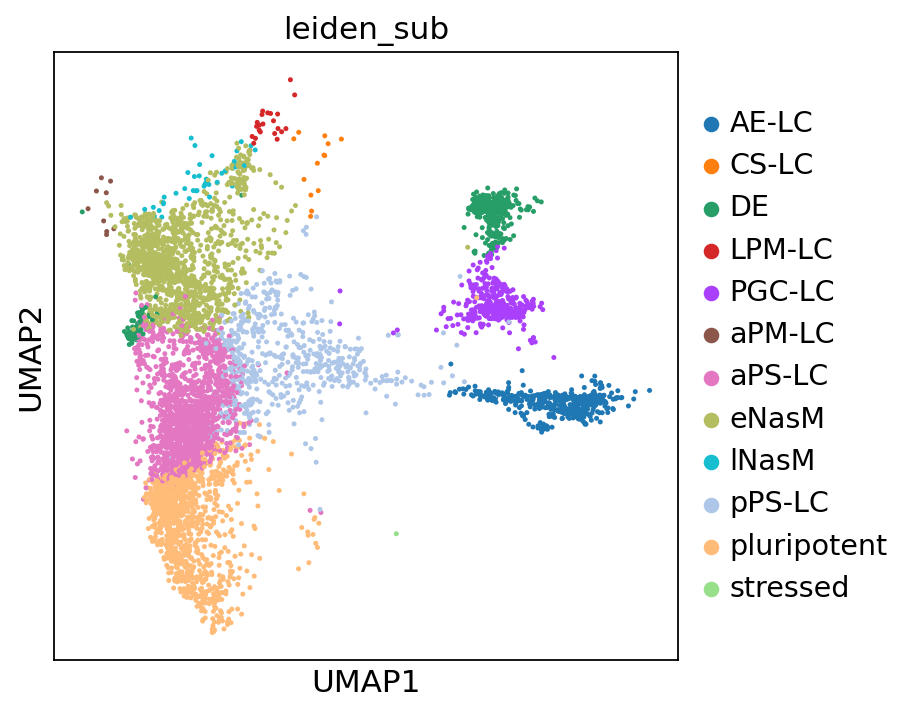

In [110]:
import gc

gc.collect()
adata = sc.read_h5ad("./data/adata_timeseries_old_48h-1.h5ad")
meta = pd.read_csv("./data/adata_timeseries_old_48h-1_meta.csv", index_col=0)
adata.obs = meta.loc[adata.obs.index]
adata.obsm["X_umap"] = np.array(
    adata.obs.loc[:, ["umap_old_48-96h_x", "umap_old_48-96h_y"]]
)
sc.pl.umap(adata, color=["leiden_sub"])
del meta

In [111]:
bonsai_gastruloid_path = pathlib.Path("./data/Bonsai_48h-1")
gas_bonsai_output_folder = bonsai_gastruloid_path / "final_bonsai_zscore0.75/"

with h5py.File(bonsai_gastruloid_path / "bonsai_vis_data.hdf", "r") as f:
    metadata = json.loads(f.attrs["metadata_json"])
gas_cell_ids = metadata["cellIds"]
print(gas_cell_ids[:5])

['AAACCCAAGCAACAAT-1_48h', 'AAACCCAAGCCACTCG-1_48h', 'AAACCCAAGGACTAAT-1_48h', 'AAACCCACACAAATAG-1_48h', 'AAACCCACACAGAGCA-1_48h']


## Compute distances

In [112]:
gas_euclidean_distances_straight = squareform(
    get_bonsai_euclidean_distances(
        final_bonsai_folder=gas_bonsai_output_folder,
        cell_ids=gas_cell_ids,
    )
)
gas_tree_distances = squareform(
    get_pdists_on_tree(
        nwk_file=gas_bonsai_output_folder / "tree.nwk",
        cell_ids=gas_cell_ids,
    )
)
gas_euclidean_distances_tree = squareform(
    get_pdists_on_tree_euclidean(
        nwk_file=gas_bonsai_output_folder / "tree.nwk",
        bonsai_output_folder=gas_bonsai_output_folder,
        cell_ids=gas_cell_ids,
    )
)

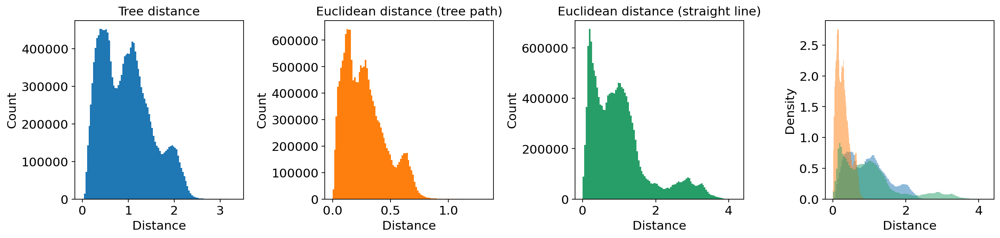

In [113]:
# check distributions
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].hist(squareform(gas_tree_distances), bins=100, color="C0")
axes[0].set_title("Tree distance")
axes[1].hist(
    squareform(gas_euclidean_distances_tree),
    bins=100,
    color="C1",
)
axes[1].set_title("Euclidean distance (tree path)")
axes[2].hist(
    squareform(gas_euclidean_distances_straight),
    bins=100,
    color="C2",
)
axes[2].set_title("Euclidean distance (straight line)")
for i, dists in enumerate(
    [gas_tree_distances, gas_euclidean_distances_tree, gas_euclidean_distances_straight]
):
    axes[3].hist(
        squareform(dists),
        bins=100,
        color=f"C{i}",
        alpha=0.5,
        density=True,
    )

for i, ax in enumerate(axes):
    ax.set_xlabel("Distance")
    ax.set_ylabel("Count") if i < 3 else ax.set_ylabel("Density")
    ax.grid(False)

plt.tight_layout()
plt.show()
plt.close()

In [114]:
# The distance distrbutions still differ a lot, do quantile based matching to match the scales
lo_pct, up_pct = 0.05, 0.95
gas_tree_distances_quantiles = np.quantile(
    squareform(gas_tree_distances), [lo_pct, up_pct]
)
gas_euclidean_distances_straight_quantiles = np.quantile(
    squareform(gas_euclidean_distances_straight), [lo_pct, up_pct]
)
gas_euclidean_distances_tree_quantiles = np.quantile(
    squareform(gas_euclidean_distances_tree), [lo_pct, up_pct]
)

# stretch euclidean distances to tree distance range
gas_euclidean_distances_straight_match = squareform(
    np.maximum(
        (
            squareform(gas_euclidean_distances_straight)
            - gas_euclidean_distances_straight_quantiles[0]
        )
        / (
            gas_euclidean_distances_straight_quantiles[1]
            - gas_euclidean_distances_straight_quantiles[0]
        )
        * (gas_tree_distances_quantiles[1] - gas_tree_distances_quantiles[0])
        + gas_tree_distances_quantiles[0],
        0,
    )
)
gas_euclidean_distances_tree_match = squareform(
    np.maximum(
        (
            squareform(gas_euclidean_distances_tree)
            - gas_euclidean_distances_tree_quantiles[0]
        )
        / (
            gas_euclidean_distances_tree_quantiles[1]
            - gas_euclidean_distances_tree_quantiles[0]
        )
        * (gas_tree_distances_quantiles[1] - gas_tree_distances_quantiles[0])
        + gas_tree_distances_quantiles[0],
        0,
    )
)

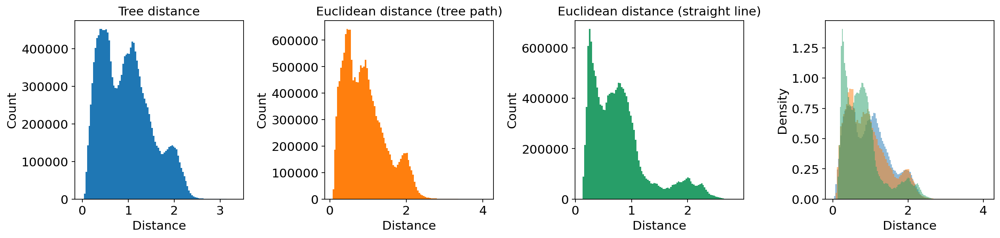

In [115]:
# check distributions
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].hist(squareform(gas_tree_distances), bins=100, color="C0")
axes[0].set_title("Tree distance")
axes[1].hist(
    squareform(gas_euclidean_distances_tree_match),
    bins=100,
    color="C1",
)
axes[1].set_title("Euclidean distance (tree path)")
axes[2].hist(
    squareform(gas_euclidean_distances_straight_match),
    bins=100,
    color="C2",
)
axes[2].set_title("Euclidean distance (straight line)")
for i, dists in enumerate(
    [
        gas_tree_distances,
        gas_euclidean_distances_tree_match,
        gas_euclidean_distances_straight_match,
    ]
):
    axes[3].hist(
        squareform(dists),
        bins=100,
        color=f"C{i}",
        alpha=0.5,
        density=True,
    )

for i, ax in enumerate(axes):
    ax.set_xlabel("Distance")
    ax.set_ylabel("Count") if i < 3 else ax.set_ylabel("Density")
    ax.grid(False)

plt.tight_layout()
plt.show()
plt.close()

## Check tree

In [116]:
f = h5py.File(bonsai_gastruloid_path / "bonsai_vis_data.hdf", "r")
coords = f["layout_coords/node_coords/ly_eq_angle"][:]
edge_coords = f["layout_coords/edge_coords/ly_eq_angle"][:]
cell_inds = f["tree_info/cell_inds"][:]
int_inds = f["tree_info/int_inds"][:]
metadata = json.loads(f.attrs["metadata_json"])
gas_cell_ids = metadata["cellIds"]
gas_vert_to_cell = json.loads(f["vert_info"].attrs["vert_ind_to_cell_inds_json"])

cell_coords = np.zeros((len(gas_cell_ids), 2))
for vert_idx_str, cell_idx in gas_vert_to_cell.items():
    vert_idx = int(vert_idx_str)
    if isinstance(cell_idx, list):
        for ci in cell_idx:
            cell_coords[ci] = coords[vert_idx]
    else:
        cell_coords[cell_idx] = coords[vert_idx]
adata.obsm["X_bonsai"] = cell_coords
f.close()

<Axes: title={'center': 'leiden_sub'}, xlabel='X_bonsai1', ylabel='X_bonsai2'>

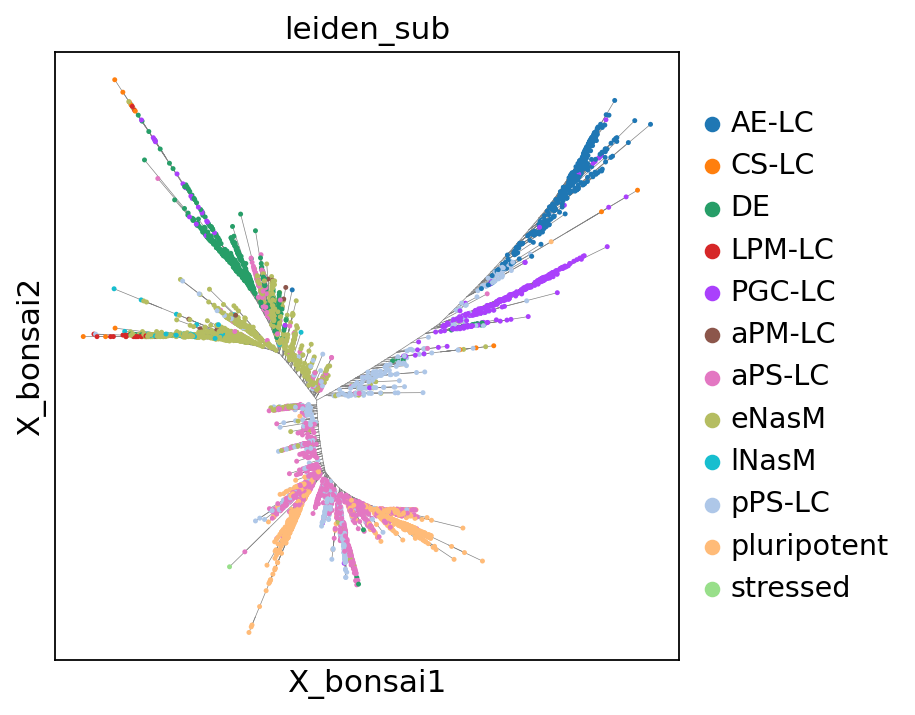

In [117]:
fig, ax = plt.subplots(figsize=(5, 5))
for e in edge_coords:
    ax.plot(e[:, 0], e[:, 1], c="gray", lw=0.3, zorder=1)
sc.pl.embedding(
    adata, basis="X_bonsai", color="leiden_sub", ax=ax, show=False, s=20, zorder=2
)

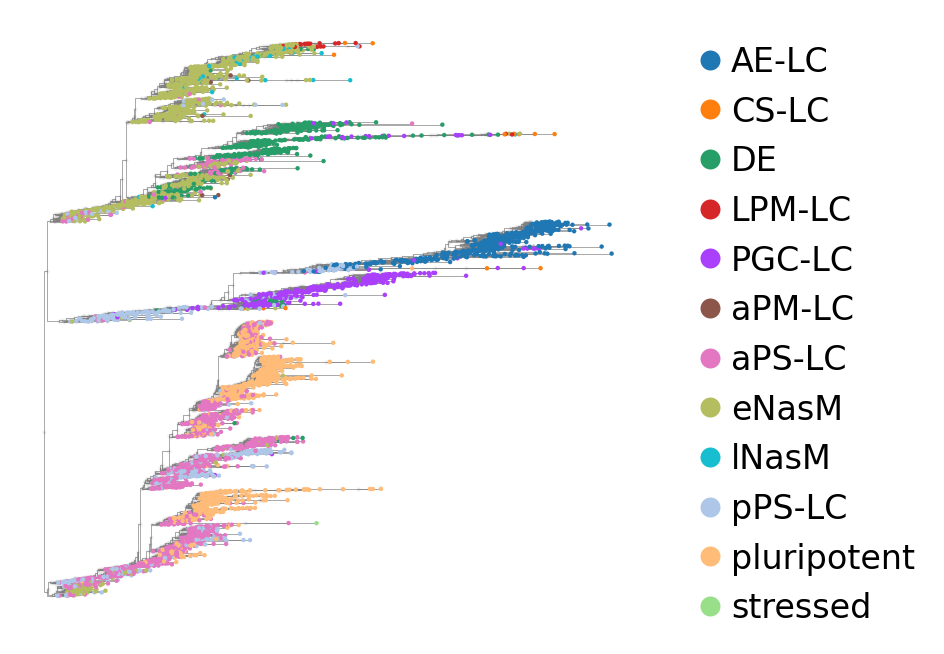

In [118]:
f = h5py.File(bonsai_gastruloid_path / "bonsai_vis_data.hdf", "r")
gas_colors = adata.uns["leiden_sub_colors"]
gas_categories = adata.obs["leiden_sub"].cat.categories
gas_cat_to_color = dict(zip(gas_categories, gas_colors))
gas_cell_colors = adata.obs["leiden_sub"].map(gas_cat_to_color).values

gas_coords_d = f["layout_coords/node_coords/ly_dendrogram_ladderized"][:]
gas_edge_coords_d = f["layout_coords/edge_coords/ly_dendrogram_ladderized"][:]

gas_cell_coords_d = np.zeros((len(gas_cell_ids), 2))
for vert_idx_str, cell_idx in gas_vert_to_cell.items():
    vert_idx = int(vert_idx_str)
    if isinstance(cell_idx, list):
        for ci in cell_idx:
            gas_cell_coords_d[ci] = gas_coords_d[vert_idx]
    else:
        gas_cell_coords_d[cell_idx] = gas_coords_d[vert_idx]

fig, ax = plt.subplots(figsize=(5, 5))
for e in gas_edge_coords_d:
    ax.plot(e[:, 0], e[:, 1], c="gray", lw=0.3, zorder=1)
ax.scatter(
    gas_coords_d[int_inds, 0],
    gas_coords_d[int_inds, 1],
    s=1,
    c="gray",
    alpha=0.1,
    zorder=2,
)
ax.scatter(
    gas_cell_coords_d[:, 0], gas_cell_coords_d[:, 1], s=1, c=gas_cell_colors, zorder=3
)
ax.set_aspect("auto")


gas_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor=gas_cat_to_color[c],
        markersize=10,
        label=c,
    )
    for c in gas_categories
]
ax.legend(
    handles=gas_handles,
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    frameon=False,
    fontsize=15,
)
ax.axis("off")
plt.show()
plt.close()
f.close()

In [119]:
gas_node_id_to_vert_ind = {}
with open(gas_bonsai_output_folder / "vertInfo.txt") as f:
    next(f)
    for line in f:
        parts = line.strip().split("\t")
        gas_node_id_to_vert_ind[parts[2]] = int(parts[0])

with open(gas_bonsai_output_folder / "tree.nwk") as f:
    nwk_str = f.read().strip()

ly_tree = Layout_Tree()
ly_tree.from_newick(nwk_str, node_id_to_vert_ind=gas_node_id_to_vert_ind)
# root node was obtained by visual inspection in web app
# was trying to make pluripotent near the root
ly_tree.reset_root(gas_node_id_to_vert_ind["internal_1880"])
ly_tree.equalAngle()
coords = ly_tree.coords.copy()

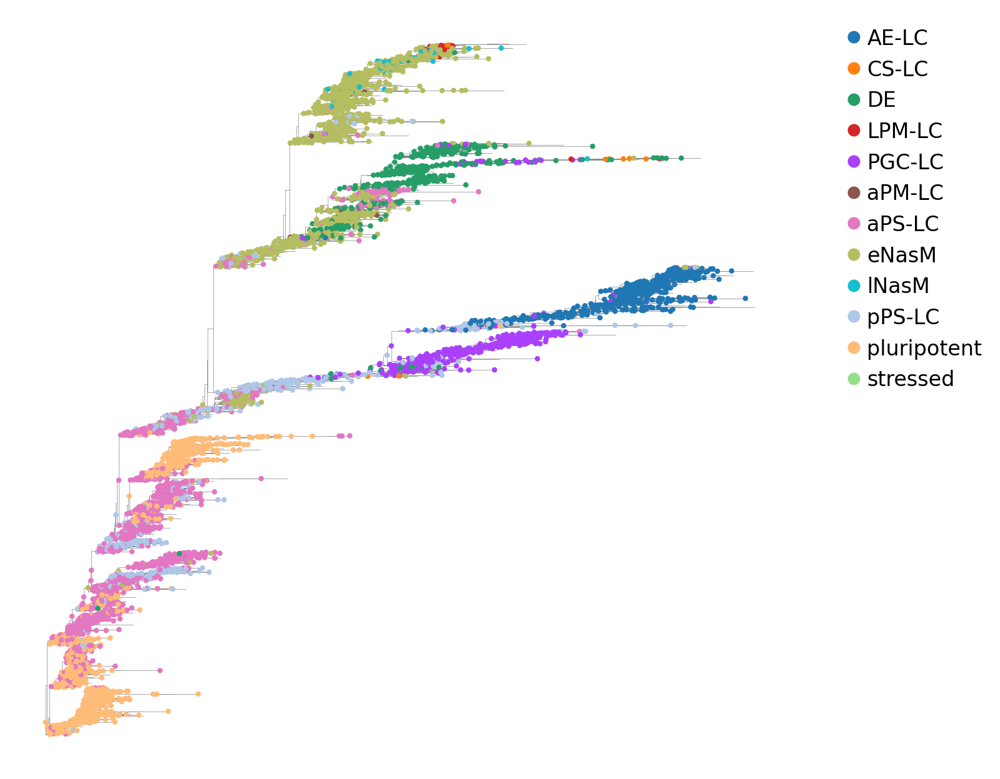

In [120]:
ly_tree.get_dendrogram(ladderized=True)
gas_coords_d = ly_tree.coords.copy()

edge_dict = ly_tree.get_edge_dict(nodeIdToVertInd=gas_node_id_to_vert_ind)
sources = edge_dict["source_ind"]
targets = edge_dict["target_ind"]

gas_edge_coords_d = np.zeros((len(sources), 3, 2))
gas_edge_coords_d[:, 0, :] = gas_coords_d[sources]
gas_edge_coords_d[:, 2, :] = gas_coords_d[targets]
gas_edge_coords_d[:, 1, 0] = gas_coords_d[sources, 0]
gas_edge_coords_d[:, 1, 1] = gas_coords_d[targets, 1]

gas_cell_coords_d = np.zeros((len(gas_cell_ids), 2))
for vert_idx_str, cell_idx in gas_vert_to_cell.items():
    vert_idx = int(vert_idx_str)
    if isinstance(cell_idx, list):
        for ci in cell_idx:
            gas_cell_coords_d[ci] = gas_coords_d[vert_idx]
    else:
        gas_cell_coords_d[cell_idx] = gas_coords_d[vert_idx]

fig, ax = plt.subplots(figsize=(10, 10))
for e in gas_edge_coords_d:
    ax.plot(e[:, 0], e[:, 1], c="gray", lw=0.3, zorder=1)
ax.scatter(
    gas_cell_coords_d[:, 0], gas_cell_coords_d[:, 1], s=8, c=gas_cell_colors, zorder=3
)
ax.set_aspect("auto")
ax.legend(
    handles=gas_handles,
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    frameon=False,
    fontsize=15,
)
ax.axis("off")
plt.show()
plt.close()

In [ ]:
from IPython.display import Image

Image("bonsai-tree-annotated.png")

## Bonsai clustering

In [121]:
annotation_dict = adata.obs["leiden_sub"].to_dict()
with open(gas_bonsai_output_folder / "tree.nwk") as f:
    nwk_str = f.read().strip()
# gas_clusters, cut_edges, nmi = bonsai_clustering.get_annotation_based_clustering_from_nwk_str(
#     tree_nwk_str=nwk_str, annotation_dict=annotation_dict, cutting_tol=0.001)
# gas_clusters = bonsai_clustering.get_max_diam_clustering_from_nwk_str(
#     tree_nwk_str=nwk_str, max_diam_threshold=1.7)
# try not to be biased by leiden annotation
all_clusters, _ = bonsai_clustering.get_min_pdists_clustering_from_nwk_str(
    tree_nwk_str=nwk_str, n_clusters=10
)
gas_clusters = all_clusters[f"annot_bnsi_cluster_n{10}"]
cluster_dict = bonsai_clustering.get_cluster_assignments({"annot": gas_clusters})
adata.obs["bonsai_cluster"] = (
    cluster_dict["annot"].reindex(adata.obs.index).fillna("-1")
)
adata.obs["bonsai_cluster"] = adata.obs["bonsai_cluster"].astype(str).astype("category")

if "bonsai_cluster_colors" in adata.uns:
    del adata.uns["bonsai_cluster_colors"]

09-16 07:49:33 mp_print INFO 
Init min-dist clustering-tree
09-16 07:49:33 mp_print INFO Clustering has created 2 subtrees, 8 branches still to cut.
09-16 07:49:33 mp_print INFO Clustering has created 4 subtrees, 6 branches still to cut.
09-16 07:49:33 mp_print INFO Clustering has created 8 subtrees, 2 branches still to cut.


Clustering done


<Axes: title={'center': 'leiden_sub'}, xlabel='X_bonsai1', ylabel='X_bonsai2'>

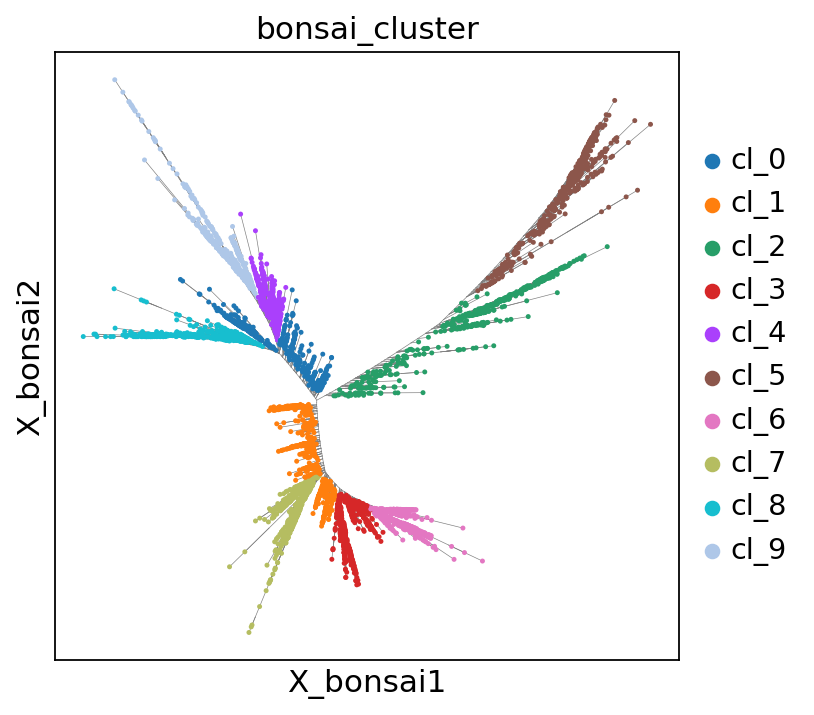

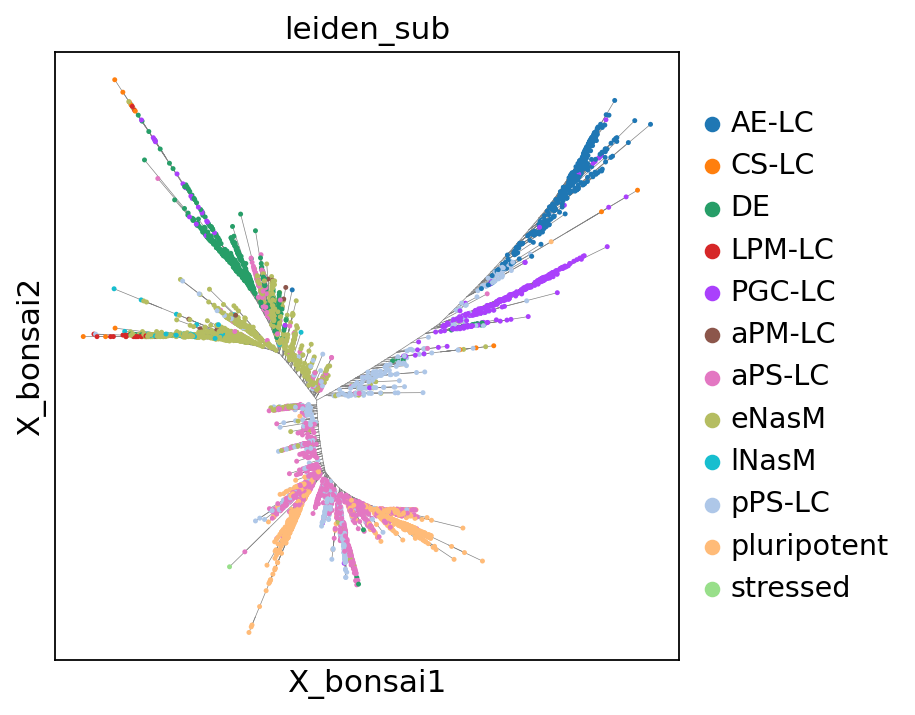

In [122]:
fig, ax = plt.subplots(figsize=(5, 5))
for e in edge_coords:
    ax.plot(e[:, 0], e[:, 1], c="gray", lw=0.3, zorder=1)
sc.pl.embedding(
    adata, basis="X_bonsai", color="bonsai_cluster", ax=ax, show=False, s=20, zorder=2
)
fig, ax = plt.subplots(figsize=(5, 5))
for e in edge_coords:
    ax.plot(e[:, 0], e[:, 1], c="gray", lw=0.3, zorder=1)
sc.pl.embedding(
    adata, basis="X_bonsai", color="leiden_sub", ax=ax, show=False, s=20, zorder=2
)

## Compute cell order

In [123]:
# to make sense of all cell to all cell, order has to be done hierachically, such as order cluster by mean t or something first then order individual cells internally
# but say i see two cells have short distance, how can i tell if tree is wrong and implies a loop or one is the other's ancestor
# probably hard to say unless i know they diverged at some point
# but also it would be difficult to interpret result if cells are not clusered by actual cell types, so still hierachical ordering is helpful
gas_cell_ids = adata.obs.index.to_list()
gas_node_id_to_vert_ind = {}
with open(gas_bonsai_output_folder / "vertInfo.txt") as f:
    next(f)
    for line in f:
        parts = line.strip().split("\t")
        gas_node_id_to_vert_ind[parts[2]] = int(parts[0])
cell_vert_inds = [gas_node_id_to_vert_ind[cid] for cid in gas_cell_ids]
cluster_vec = adata.obs.loc[gas_cell_ids, "bonsai_cluster"].copy()
gas_clusters = cluster_vec.cat.categories
gas_root_id = "internal_1880"

gas_G = nx.Graph()
with open(gas_bonsai_output_folder / "edgeInfo.txt") as f:
    for line in f:
        v1, v2, d = line.strip().split("\t")
        gas_G.add_edge(int(v1), int(v2), weight=float(d))
gas__tree_t = nx.shortest_path_length(
    gas_G, source=gas_node_id_to_vert_ind[gas_root_id], weight="weight"
)
gas_dists_to_root = np.array([gas__tree_t[cvid] for cvid in cell_vert_inds])
gas_dists_to_root_by_cluster = np.zeros(len(gas_cell_ids))
for c in gas_clusters:
    gas_dists_to_root_by_cluster[cluster_vec == c] = np.mean(
        gas_dists_to_root[cluster_vec == c]
    )
gas_reorder_ind = np.lexsort((gas_dists_to_root, gas_dists_to_root_by_cluster))

In [124]:
gas_dist_matrix_tree_t_ordered = gas_tree_distances[gas_reorder_ind, :][
    :, gas_reorder_ind
]
gas_dist_matrix_tree_e_ordered = gas_euclidean_distances_tree_match[gas_reorder_ind, :][
    :, gas_reorder_ind
]
gas_dist_matrix_straight_ordered = gas_euclidean_distances_straight_match[
    gas_reorder_ind, :
][:, gas_reorder_ind]

In [125]:
gas_window_size = 20
gas_cell_types = pd.Categorical(adata.obs["leiden_sub"]).categories
gas_colors = adata.uns["leiden_sub_colors"]
gas_cell_composition_matrix = np.zeros((len(gas_cell_types) + 1, len(gas_cell_ids)))
for i, cell_type in enumerate(gas_cell_types):
    res = np.convolve(
        adata.obs.loc[gas_cell_ids, "leiden_sub"].iloc[gas_reorder_ind] == cell_type,
        np.ones(gas_window_size),
        mode="valid",
    )
    margin = int(np.ceil((gas_cell_composition_matrix.shape[1] - res.shape[0]) / 2))
    res = np.pad(res, (margin, margin), mode="constant")
    gas_cell_composition_matrix[i, :] = res[: gas_cell_composition_matrix.shape[1]]
gas_cell_composition_matrix[-1, :] = 1
gas_cell_composition_matrix = gas_cell_composition_matrix / np.sum(
    gas_cell_composition_matrix, axis=0
)

## Plot heatmaps

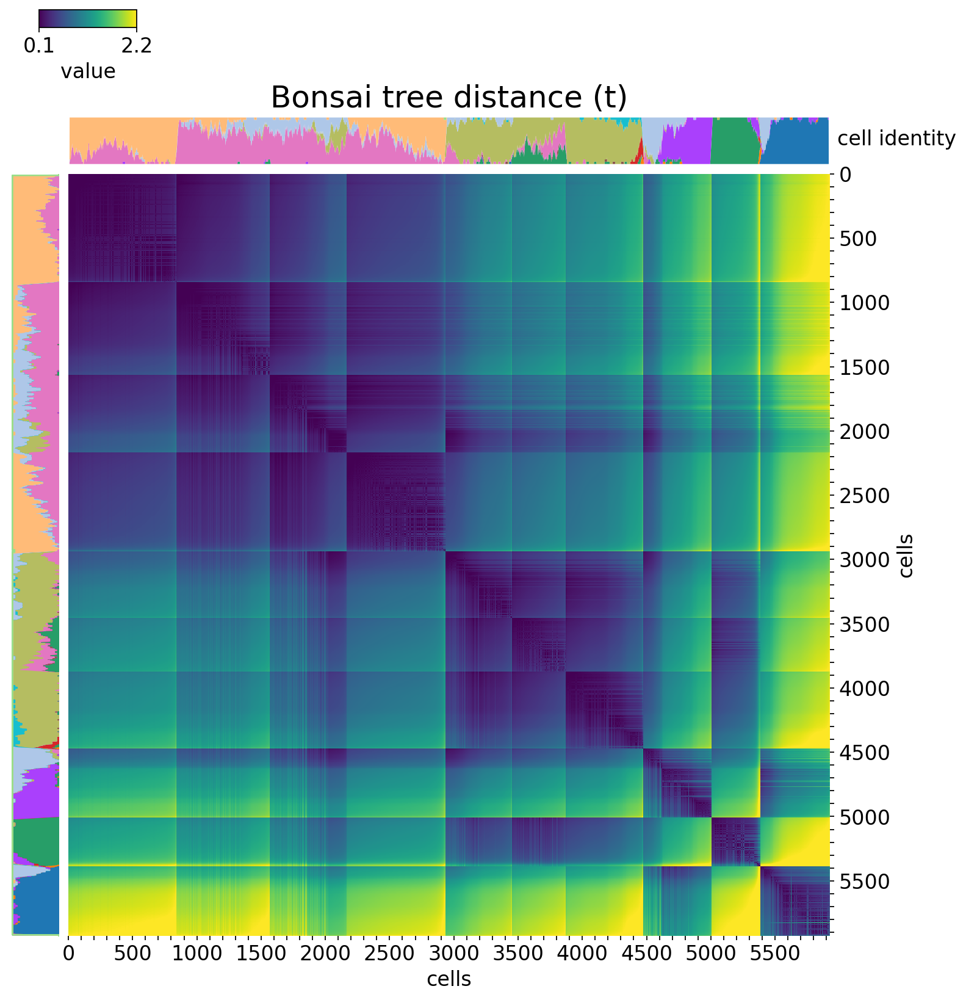

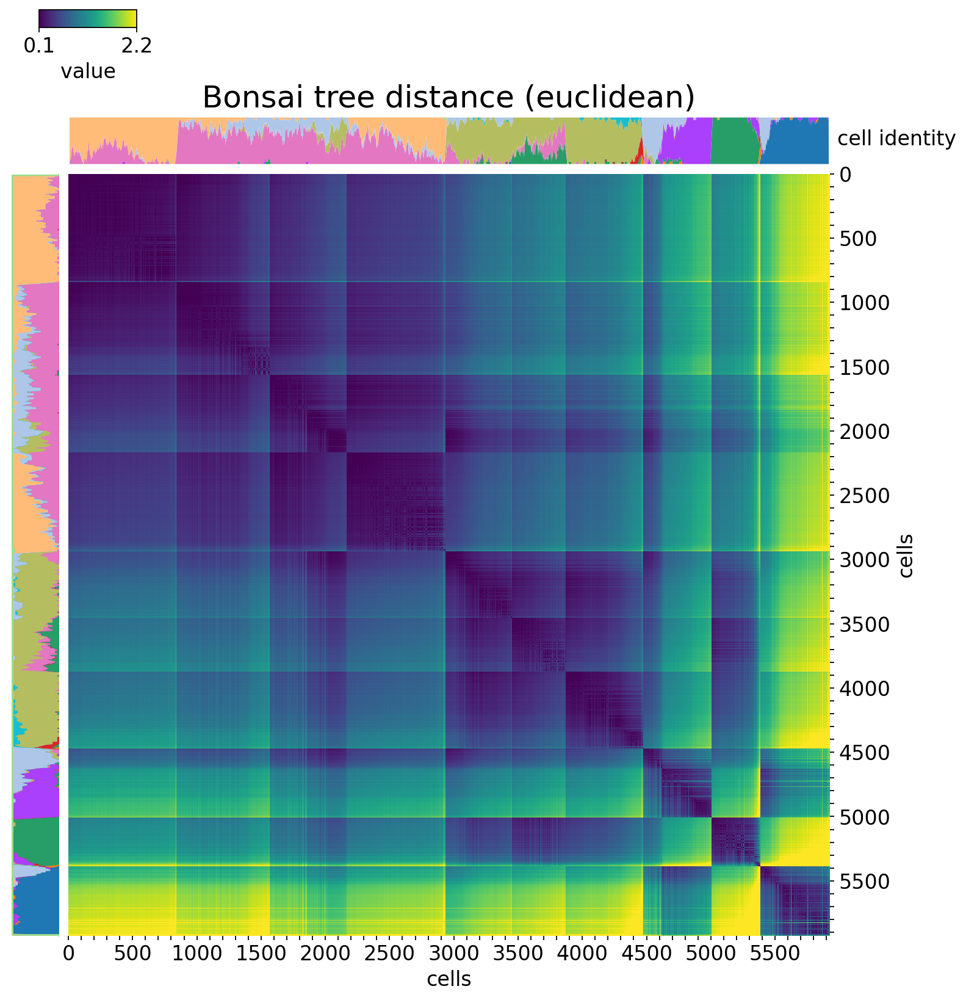

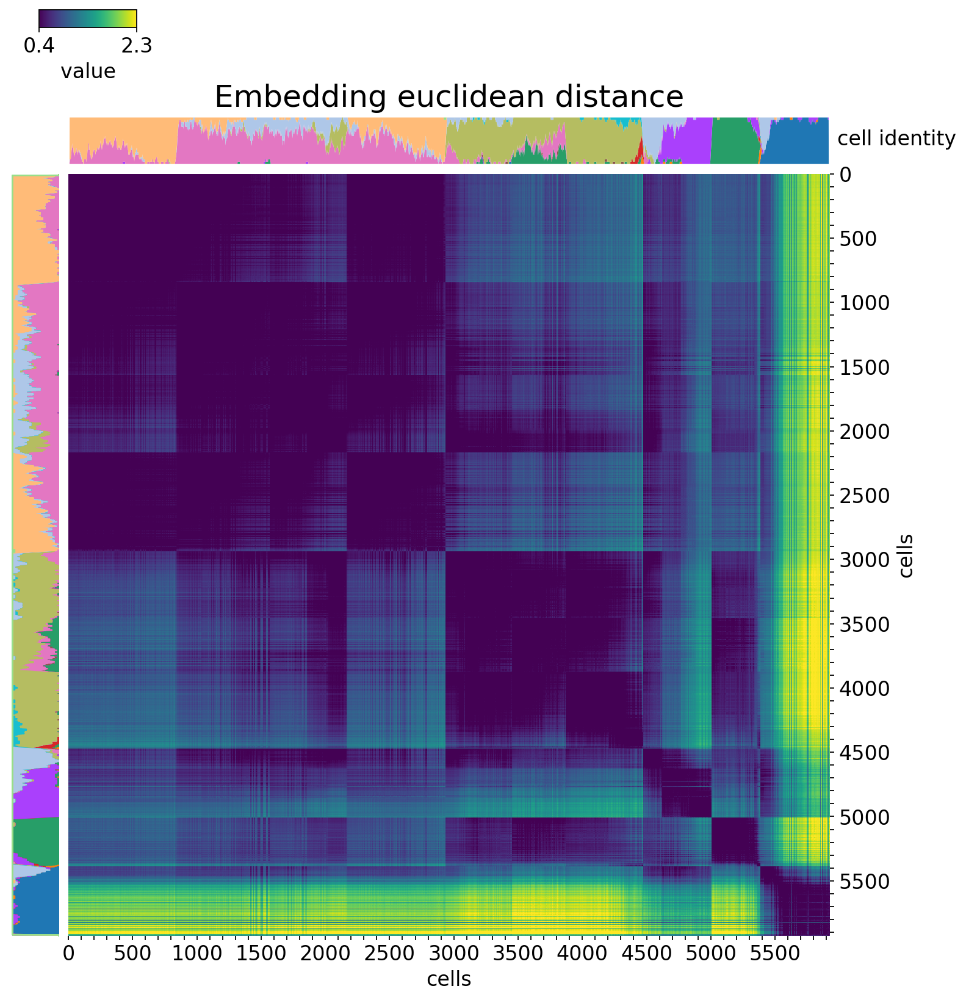

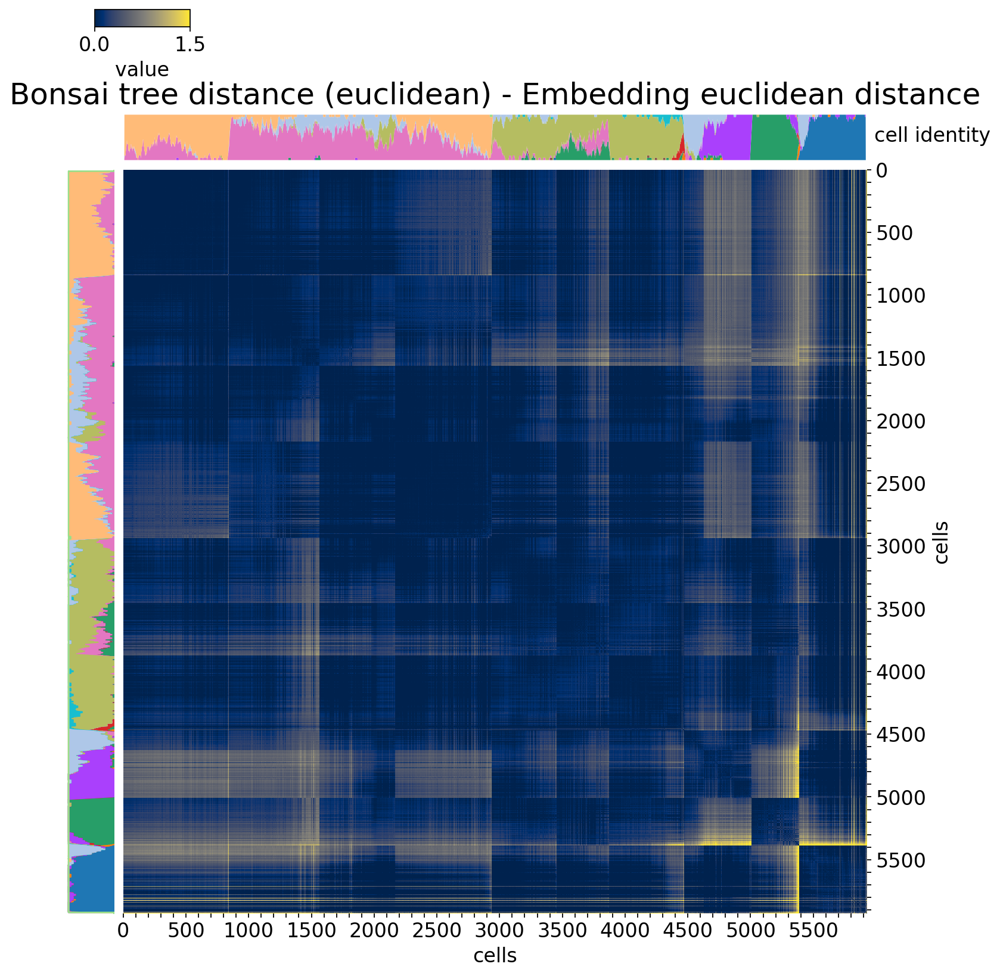

In [21]:
FONTSIZE = 15
heatmaps = [
    {
        "mat": gas_dist_matrix_tree_t_ordered,
        "title": "Bonsai tree distance (t)",
        "cmap": "viridis",
        "vmin_pct": 1,
        "vmax_pct": 99,
        "vmin": None,
        "vmax": None,
    },
    {
        "mat": gas_dist_matrix_tree_e_ordered,
        "title": "Bonsai tree distance (euclidean)",
        "cmap": "viridis",
        "vmin_pct": 1,
        "vmax_pct": 99,
        "vmin": None,
        "vmax": None,
    },
    {
        "mat": gas_dist_matrix_straight_ordered,
        "title": "Embedding euclidean distance",
        "cmap": "viridis",
        "vmin_pct": 25,
        "vmax_pct": 99,
        "vmin": None,
        "vmax": None,
    },
    {
        "mat": gas_dist_matrix_tree_e_ordered - gas_dist_matrix_straight_ordered,
        "title": "Bonsai tree distance (euclidean) - Embedding euclidean distance",
        "cmap": "cividis",
        "vmin_pct": 1,
        "vmax_pct": 99,
        "vmin": 0.0,
        "vmax": 1.5,
    },
]

for i, heatmap in enumerate(heatmaps):
    # make sure matrix is symmetric
    plot_mat = (heatmap["mat"] + heatmap["mat"].T) / 2

    # simple linear percentile color scaling
    vmin_pct = heatmap["vmin_pct"]
    vmax_pct = heatmap["vmax_pct"]
    if vmin_pct is None:
        vmin_pct = 0
    if vmax_pct is None:
        vmax_pct = 100
    vmin = (
        np.percentile(plot_mat, vmin_pct)
        if heatmap["vmin"] is None
        else heatmap["vmin"]
    )
    vmax = (
        np.percentile(plot_mat, vmax_pct)
        if heatmap["vmax"] is None
        else heatmap["vmax"]
    )
    norm = Normalize(vmin=vmin, vmax=vmax)

    g = sns.clustermap(
        plot_mat,
        cmap=heatmap["cmap"],
        cbar=True,
        square=False,
        xticklabels=False,
        yticklabels=False,
        row_cluster=False,
        col_cluster=False,
        figsize=(10, 10),
        rasterized=True,
        norm=norm,
    )
    ax_hm = g.ax_heatmap
    ax_hm.set_aspect("equal")
    g.ax_row_dendrogram.set_visible(False)
    g.ax_col_dendrogram.set_visible(False)
    g.cax.set_visible(False)

    ax_hm.set_position([0.1, 0.08, 0.78, 0.78])
    pos = ax_hm.get_position()

    n = plot_mat.shape[1]
    n_rows = plot_mat.shape[0]
    x = np.arange(n)
    y = np.arange(n_rows)

    tick_x = np.arange(0, n, 100)
    tick_x_labels = [str(int(t)) if t % 500 == 0 else "" for t in tick_x]
    ax_hm.set_xticks(tick_x)
    ax_hm.set_xticklabels(tick_x_labels, fontsize=FONTSIZE)
    ax_hm.tick_params(axis="x", which="major", length=3, direction="out")
    ax_hm.grid(False)

    tick_y = np.arange(0, n_rows, 100)
    tick_y_labels = [str(int(t)) if t % 500 == 0 else "" for t in tick_y]
    ax_hm.set_yticks(tick_y)
    ax_hm.set_yticklabels(tick_y_labels, fontsize=FONTSIZE)
    ax_hm.tick_params(axis="y", which="major", length=3, direction="out")
    ax_hm.set_xlabel("cells", fontsize=FONTSIZE)
    ax_hm.set_ylabel("cells", fontsize=FONTSIZE)

    ax_top = g.fig.add_axes([pos.x0, pos.y1 + 0.01, pos.width, 0.05])
    ax_top.stackplot(
        x, gas_cell_composition_matrix[:-1, :], labels=gas_cell_types, colors=gas_colors
    )
    ax_top.set_xlim(ax_hm.get_xlim())
    ax_top.axis("off")
    ax_top.text(
        1.01,
        0.5,
        "cell identity",
        transform=ax_top.transAxes,
        ha="left",
        va="center",
        rotation=0,
        fontsize=FONTSIZE,
        clip_on=False,
    )

    ax_left = g.fig.add_axes([pos.x0 - 0.06, pos.y0, 0.05, pos.height])
    cumulative = np.cumsum(gas_cell_composition_matrix[:-1, :], axis=0)
    prev = np.zeros(n_rows)
    for k in range(cumulative.shape[0]):
        ax_left.fill_betweenx(y, prev, cumulative[k], color=gas_colors[k])
        prev = cumulative[k]
    ax_left.set_xlim(1, 0)
    ax_left.set_ylim(ax_hm.get_ylim())
    ax_left.axis("off")

    ax_top.set_title(heatmap["title"], fontsize=FONTSIZE * 1.5)

    mappable = ScalarMappable(norm=norm, cmap=heatmap["cmap"])
    mappable.set_array([])
    cax = g.fig.add_axes([pos.x0 - 0.03, 1.01, 0.1, 0.018])
    cb = g.fig.colorbar(mappable, cax=cax, orientation="horizontal")
    cb.set_label("value", fontsize=FONTSIZE, labelpad=4)
    if vmin < 0 < vmax:
        cb.set_ticks([vmin, 0, vmax], labels=[f"{vmin:.1f}", "0", f"{vmax:.1f}"])
    else:
        cb.set_ticks([vmin, vmax], labels=[f"{vmin:.1f}", f"{vmax:.1f}"])
    cb.ax.tick_params(labelsize=FONTSIZE)

    plt.show()
    plt.close()
    gc.collect()

In [ ]:
convergence_matrix = gas_dist_matrix_tree_e_ordered - gas_dist_matrix_straight_ordered

In [36]:
np.save("convergence_matrix.npy", convergence_matrix)

In [5]:
convergence_matrix = np.load("convergence_matrix.npy")

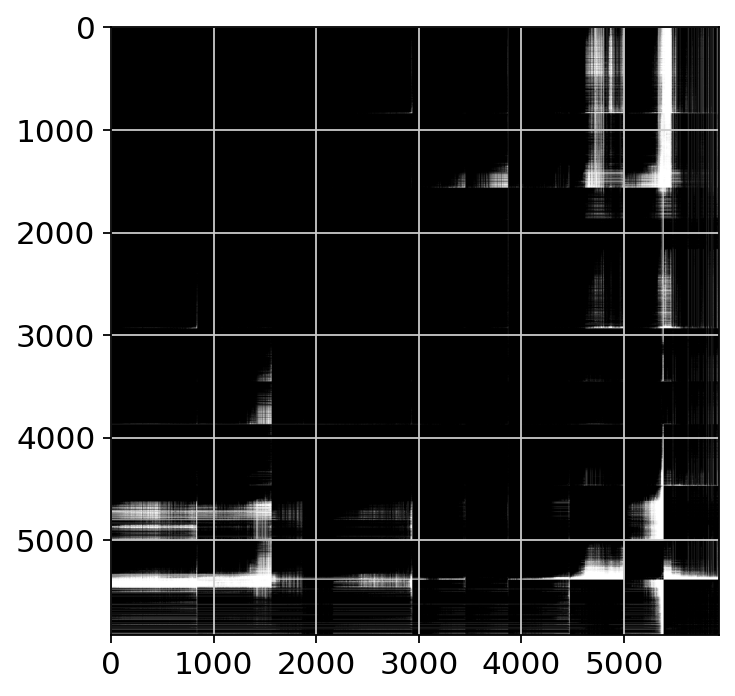

In [64]:
plt.imshow((convergence_matrix > 0.6).astype(int), cmap="gray")

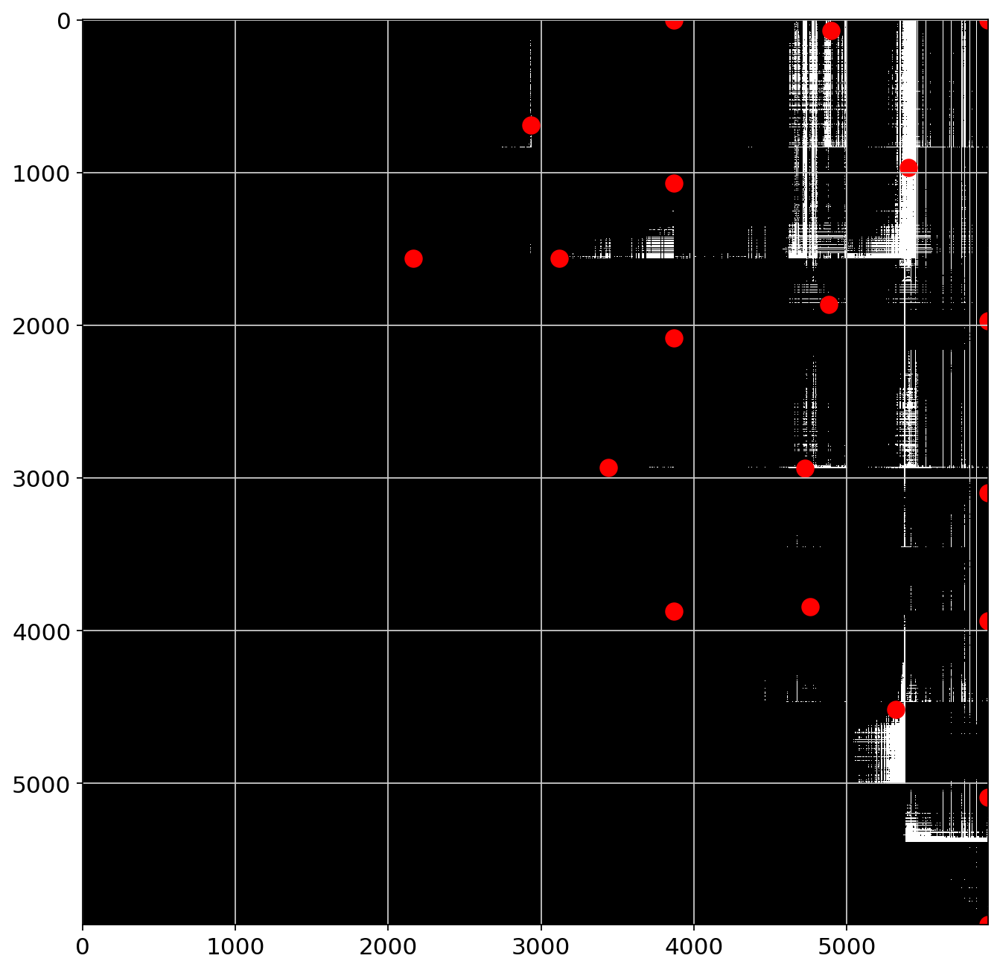

In [65]:
from scipy.signal import convolve2d

convergence_matri_bin = np.triu(convergence_matrix > 0.6)
pts_pos = np.stack(np.where(convergence_matri_bin), axis=1)
pts_pos_density = convolve2d(
    convergence_matri_bin, np.ones((50, 50)), mode="same", boundary="fill", fillvalue=0
)
density = pts_pos_density[pts_pos[:, 0], pts_pos[:, 1]]
pts_seeds = sample_farthest_points(embedding=pts_pos, density=density, n=20)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(convergence_matri_bin, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
ax.autoscale(False)  # keep imshow's limits; scatter won't pad the axes
ax.scatter(pts_pos[pts_seeds, 1], pts_pos[pts_seeds, 0], c="red", s=100)
plt.show()

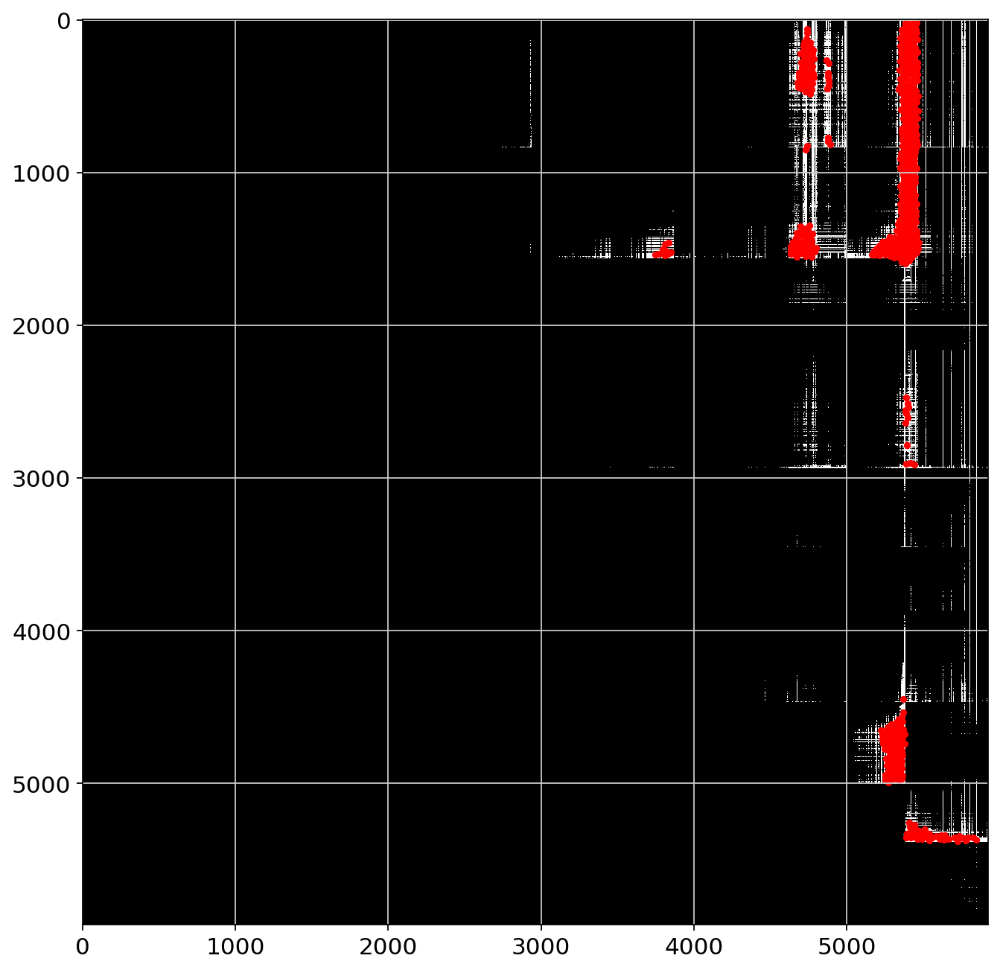

In [70]:
pts_seeds = sample_farthest_points(
    embedding=pts_pos, density=density, n=5000, random_state=1
)
pts_seeds_sub = pts_seeds[density[pts_seeds] > 1500]

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(convergence_matri_bin, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
ax.autoscale(False)  # keep imshow's limits; scatter won't pad the axes
ax.scatter(pts_pos[pts_seeds_sub, 1], pts_pos[pts_seeds_sub, 0], c="red", s=10)
plt.show()

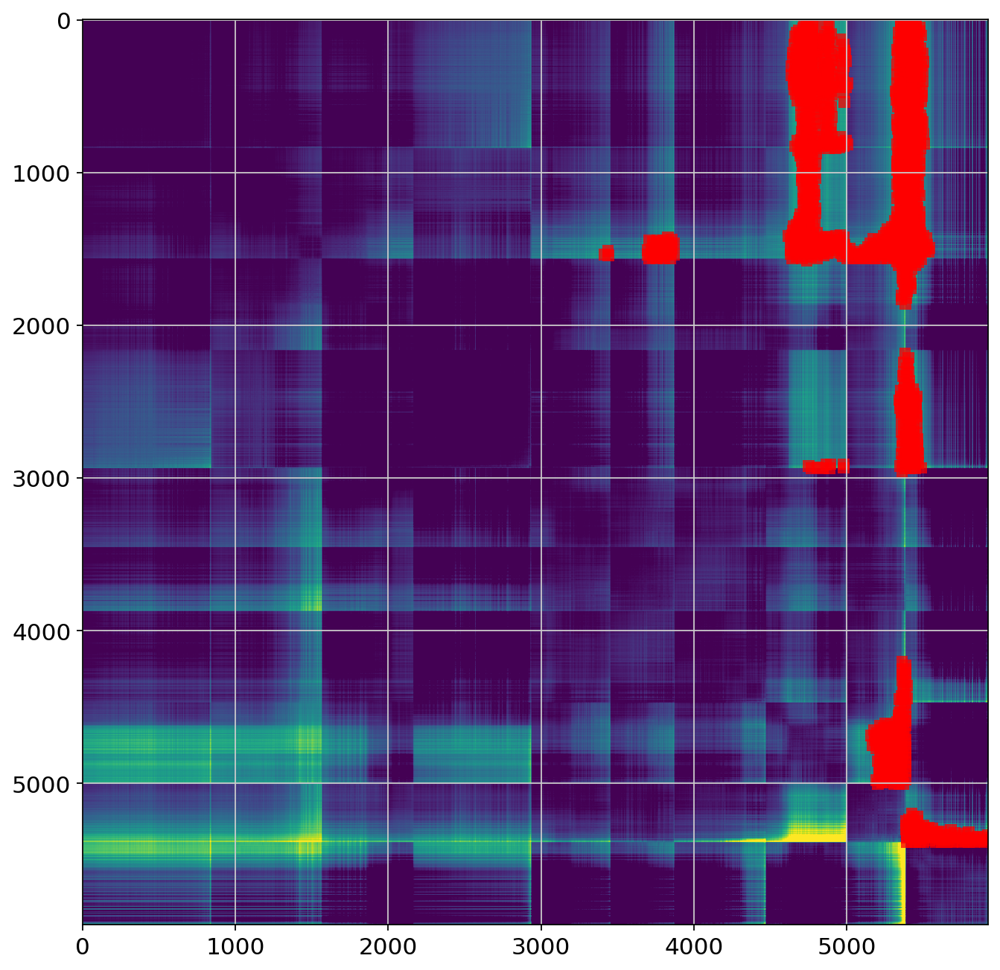

In [95]:
pts_seeds_sub = pts_seeds[density[pts_seeds] > 700]
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(convergence_matrix, cmap="viridis", vmin=0, vmax=1)
ax.autoscale(False)  # keep imshow's limits; scatter won't pad the axes
ax.scatter(
    pts_pos[pts_seeds_sub, 1],
    pts_pos[pts_seeds_sub, 0],
    c="red",
    s=50,
    marker="s",
    alpha=0.75,
    edgecolor="none",
)
plt.show()

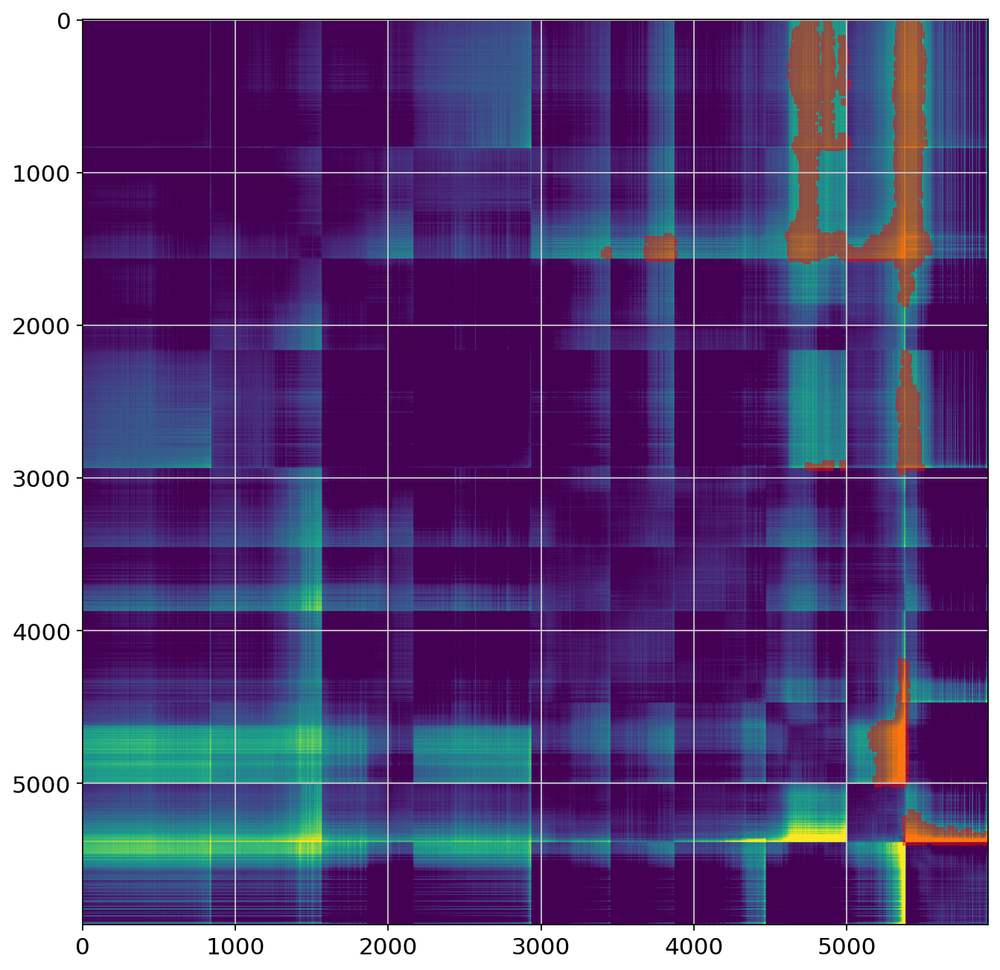

In [98]:
from matplotlib.colors import ListedColormap
from scipy.ndimage import binary_dilation

seed_mask = np.zeros(convergence_matrix.shape, bool)
seed_mask[pts_pos[pts_seeds_sub, 0], pts_pos[pts_seeds_sub, 1]] = True
blocks = binary_dilation(seed_mask, structure=np.ones((50, 50), bool))

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(convergence_matrix, cmap="viridis", vmin=0, vmax=1)
ax.imshow(
    np.ma.masked_where(~blocks, blocks),
    cmap=ListedColormap(["red"]),
    alpha=0.5,
    interpolation="nearest",
)
plt.show()

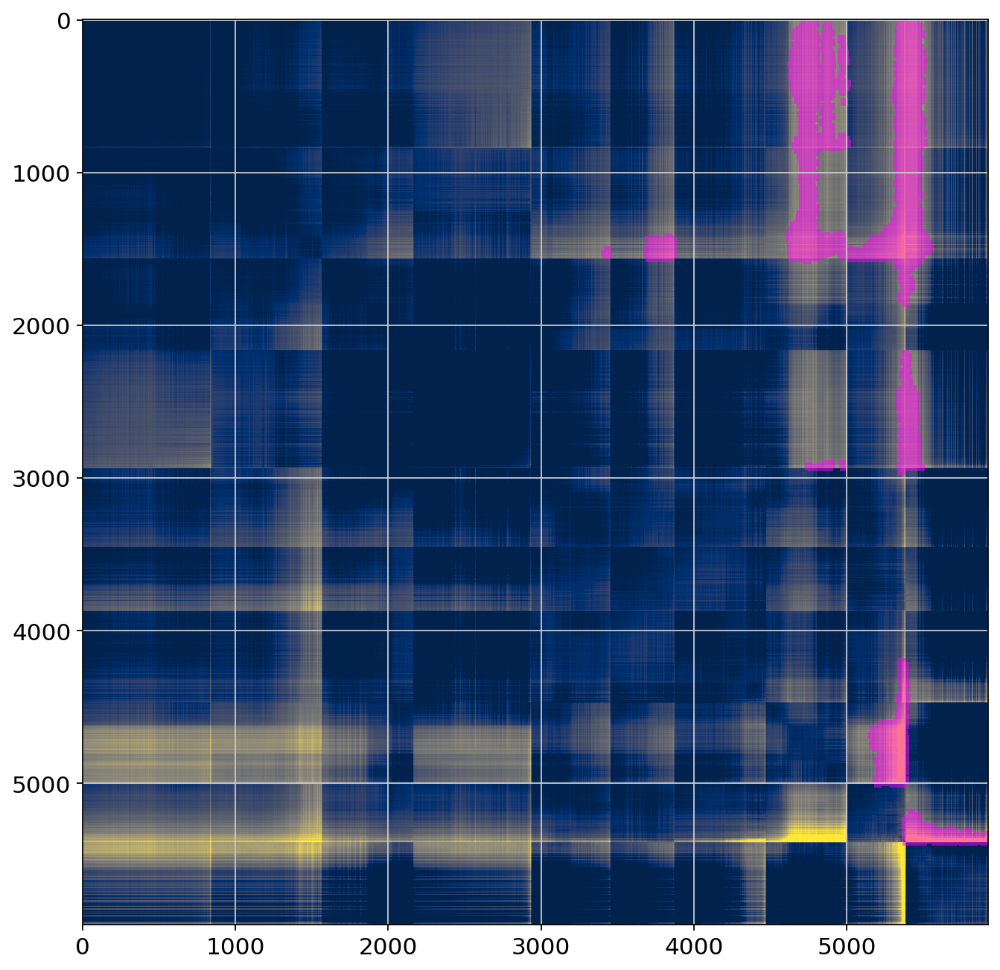

In [132]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(convergence_matrix, cmap="cividis", vmin=0, vmax=1)
ax.imshow(
    np.ma.masked_where(~blocks, blocks),
    cmap=ListedColormap(["magenta"]),
    alpha=0.5,
    interpolation="nearest",
)
# ax.grid(False)
# ax.axis("off")
# plt.savefig("convergence_matrix_patch.png", dpi=300, bbox_inches="tight")
plt.show()

PGC-LC in block: 377 / 378
DE in block:     424 / 499


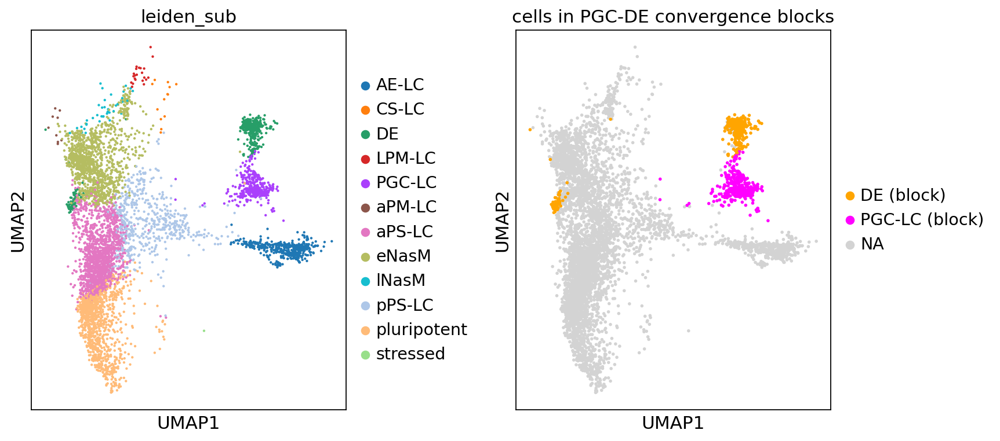

In [136]:
# --- highlight PGC-DE convergence-block cells on UMAP ---
# blocks lives in reordered index space (rows/cols = gas_reorder_ind) and is
# upper-triangular because convergence_matri_bin came from np.triu; symmetrize first
blocks_sym = blocks | blocks.T

types_ordered = adata.obs.loc[gas_cell_ids, "leiden_sub"].iloc[gas_reorder_ind].values
is_pgc = types_ordered == "PGC-LC"
is_de = types_ordered == "DE"

# keep only block entries whose two cells are one PGC-LC and one DE
pgc_de_pair = (is_pgc[:, None] & is_de[None, :]) | (is_de[:, None] & is_pgc[None, :])
block_pgc_de = blocks_sym & pgc_de_pair

# a cell is "in the block" if it pairs with at least one cell of the other type
in_block_ordered = block_pgc_de.any(axis=1)
cell_ids_ordered = np.array(gas_cell_ids)[gas_reorder_ind]
pgc_block_ids = cell_ids_ordered[in_block_ordered & is_pgc]
de_block_ids = cell_ids_ordered[in_block_ordered & is_de]
print(f"PGC-LC in block: {len(pgc_block_ids)} / {is_pgc.sum()}")
print(f"DE in block:     {len(de_block_ids)} / {is_de.sum()}")

adata.obs["pgc_de_block"] = "other"
adata.obs.loc[pgc_block_ids, "pgc_de_block"] = "PGC-LC (block)"
adata.obs.loc[de_block_ids, "pgc_de_block"] = "DE (block)"
adata.obs["pgc_de_block"] = pd.Categorical(
    adata.obs["pgc_de_block"], categories=["other", "PGC-LC (block)", "DE (block)"]
)
adata.uns.pop("pgc_de_block_colors", None)  # drop stale palette if cell is rerun

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
sc.pl.umap(adata, color="leiden_sub", ax=axes[0], show=False, s=15, title="leiden_sub")
# grey background, then block cells drawn on top so they are not buried
sc.pl.umap(
    adata,
    color="pgc_de_block",
    groups=["PGC-LC (block)", "DE (block)"],
    palette={
        "other": "lightgrey",
        "PGC-LC (block)": "magenta",
        "DE (block)": "orange",
    },
    na_color="lightgrey",
    ax=axes[1],
    show=False,
    s=25,
    title="cells in PGC-DE convergence blocks",
)
plt.tight_layout()
plt.show()

66775 PGC-DE pairs, 377 PGC-LC cells, 424 DE cells


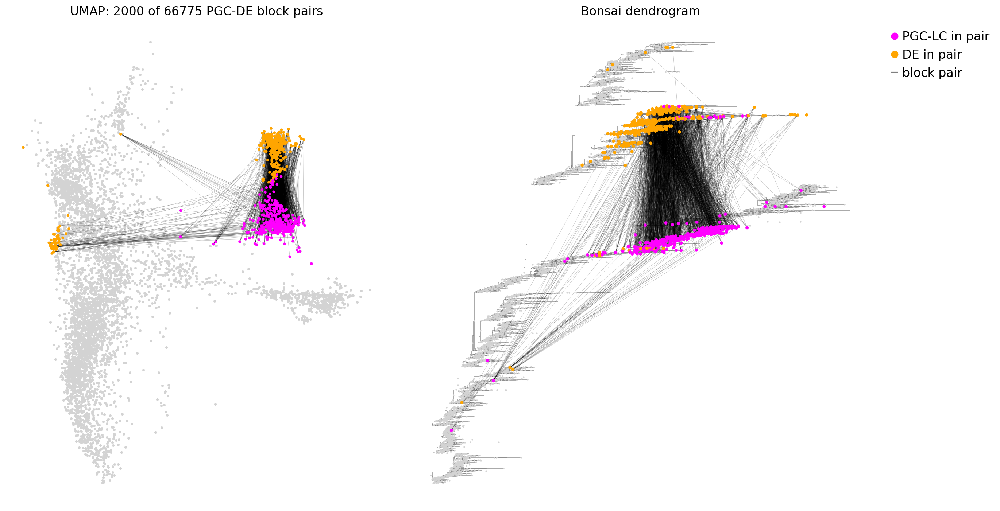

In [141]:
FONTSIZE = 15
from matplotlib.collections import LineCollection

# --- PGC-DE cell pairs inside the convergence blocks ---
blocks_sym = blocks | blocks.T  # blocks came from np.triu, so symmetrize
types_ordered = adata.obs.loc[gas_cell_ids, "leiden_sub"].iloc[gas_reorder_ind].values
is_pgc = types_ordered == "PGC-LC"
is_de = types_ordered == "DE"

# keep block entries where the row is PGC-LC and the column is DE (one direction is enough)
block_pgc_de = blocks_sym & (is_pgc[:, None] & is_de[None, :])
row_ord, col_ord = np.where(block_pgc_de)

# map reordered indices back to positions in adata.obs / gas_cell_coords_d
pgc_idx = gas_reorder_ind[row_ord]
de_idx = gas_reorder_ind[col_ord]
print(
    f"{len(pgc_idx)} PGC-DE pairs, "
    f"{len(np.unique(pgc_idx))} PGC-LC cells, {len(np.unique(de_idx))} DE cells"
)

# subsample pairs for drawing; every line is one pair
n_draw = 2000
rng = np.random.default_rng(0)
sel = rng.choice(len(pgc_idx), size=min(n_draw, len(pgc_idx)), replace=False)
pgc_sel, de_sel = pgc_idx[sel], de_idx[sel]

in_pair = np.zeros(adata.n_obs, bool)
in_pair[pgc_idx] = True
in_pair[de_idx] = True
pair_colors = np.where(is_pgc[np.argsort(gas_reorder_ind)], "magenta", "orange")


def draw_pairs(ax, xy, edge_coords=None, s_bg=2, s_fg=12):
    # background: tree edges (dendrogram only) plus all cells in grey
    if edge_coords is not None:
        for e in edge_coords:
            ax.plot(e[:, 0], e[:, 1], c="gray", lw=0.3, zorder=1)
    ax.scatter(xy[:, 0], xy[:, 1], s=s_bg, c="lightgrey", zorder=2, linewidths=0)
    # one line per PGC-DE pair
    segs = np.stack([xy[pgc_sel], xy[de_sel]], axis=1)
    ax.add_collection(
        LineCollection(segs, colors="black", linewidths=0.3, alpha=0.3, zorder=3)
    )
    # paired cells on top, coloured by type
    ax.scatter(
        xy[in_pair, 0],
        xy[in_pair, 1],
        s=s_fg,
        c=pair_colors[in_pair],
        zorder=4,
        linewidths=0,
    )
    ax.set_aspect("equal")
    ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(18, 9))
draw_pairs(axes[0], adata.obsm["X_umap"], s_bg=10)
axes[0].set_title(
    f"UMAP: {len(sel)} of {len(pgc_idx)} PGC-DE block pairs", fontsize=FONTSIZE
)
draw_pairs(axes[1], gas_cell_coords_d, edge_coords=gas_edge_coords_d, s_bg=4, s_fg=16)
axes[1].set_aspect("auto")
axes[1].set_title("Bonsai dendrogram", fontsize=FONTSIZE)

handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="magenta",
        markersize=10,
        label="PGC-LC in pair",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="orange",
        markersize=10,
        label="DE in pair",
    ),
    Line2D([0], [0], color="black", lw=1, alpha=0.5, label="block pair"),
]
axes[1].legend(
    handles=handles,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
    fontsize=FONTSIZE,
)
plt.tight_layout()
plt.show()

56194 pairs in patch
row-side cells: {'PGC-LC': 339, 'pPS-LC': 136, 'DE': 38, 'eNasM': 9, 'aPS-LC': 4, 'CS-LC': 3, 'LPM-LC': 0, 'AE-LC': 0, 'aPM-LC': 0, 'lNasM': 0, 'pluripotent': 0, 'stressed': 0}
col-side cells: {'DE': 58, 'PGC-LC': 20, 'pPS-LC': 16, 'AE-LC': 6, 'CS-LC': 5, 'LPM-LC': 2, 'eNasM': 2, 'aPS-LC': 1, 'lNasM': 1, 'aPM-LC': 0, 'pluripotent': 0, 'stressed': 0}


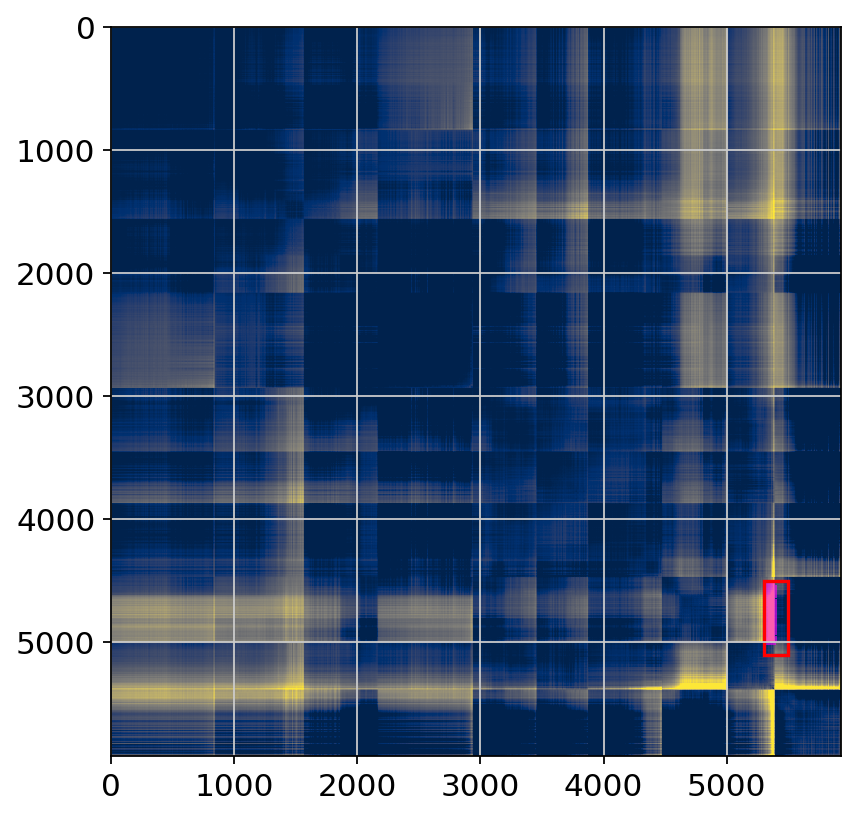

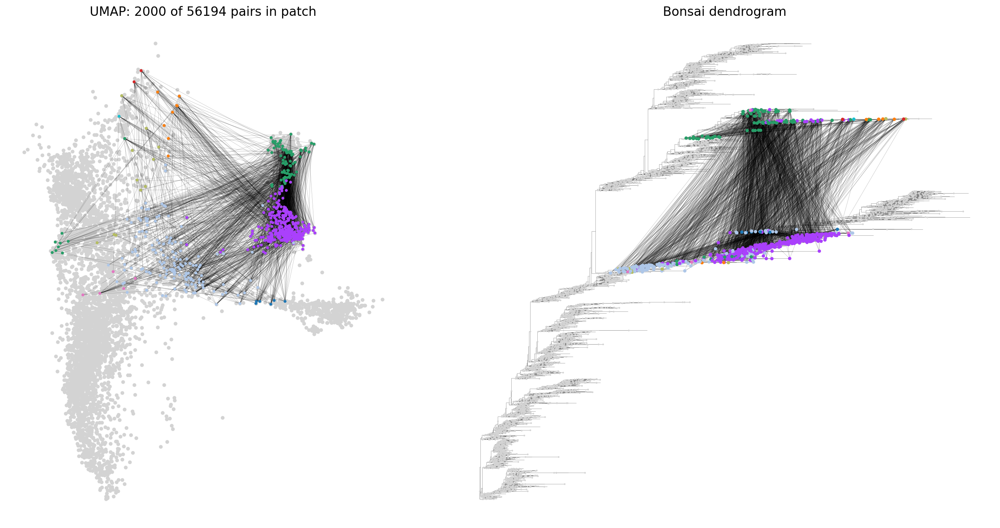

In [147]:
# --- select only the patch in the red box (reordered-matrix coordinates) ---
row_lo, row_hi = 4500, 5100
col_lo, col_hi = 5300, 5500

blocks_sym = blocks | blocks.T
patch_mask = np.zeros_like(blocks_sym)
patch_mask[row_lo:row_hi, col_lo:col_hi] = True
patch = blocks_sym & patch_mask
row_ord, col_ord = np.where(patch)
print(f"{len(row_ord)} pairs in patch")

# map back to adata.obs positions and check what the two sides are
a_idx = gas_reorder_ind[row_ord]
b_idx = gas_reorder_ind[col_ord]
types = adata.obs["leiden_sub"].values
print("row-side cells:", pd.Series(types[np.unique(a_idx)]).value_counts().to_dict())
print("col-side cells:", pd.Series(types[np.unique(b_idx)]).value_counts().to_dict())

# subsample lines for drawing
n_draw = 2000
rng = np.random.default_rng(0)
sel = rng.choice(len(a_idx), size=min(n_draw, len(a_idx)), replace=False)
pgc_sel, de_sel = a_idx[sel], b_idx[sel]  # names kept so draw_pairs works unchanged

in_pair = np.zeros(adata.n_obs, bool)
in_pair[a_idx] = True
in_pair[b_idx] = True
# colour paired cells by their actual leiden_sub colour
gas_cat_to_color = dict(
    zip(adata.obs["leiden_sub"].cat.categories, adata.uns["leiden_sub_colors"])
)
pair_colors = adata.obs["leiden_sub"].map(gas_cat_to_color).values

# sanity check: show the patch on the convergence matrix
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(convergence_matrix, cmap="cividis", vmin=0, vmax=1)
ax.imshow(
    np.ma.masked_where(~patch, patch),
    cmap=ListedColormap(["magenta"]),
    alpha=0.6,
    interpolation="nearest",
)
ax.add_patch(
    plt.Rectangle(
        (col_lo, row_lo), col_hi - col_lo, row_hi - row_lo, fill=False, ec="red", lw=1.5
    )
)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(18, 9))
draw_pairs(axes[0], adata.obsm["X_umap"], s_bg=20)
axes[0].set_title(f"UMAP: {len(sel)} of {len(a_idx)} pairs in patch", fontsize=FONTSIZE)
draw_pairs(axes[1], gas_cell_coords_d, edge_coords=gas_edge_coords_d, s_bg=4, s_fg=16)
axes[1].set_aspect("auto")
axes[1].set_title("Bonsai dendrogram", fontsize=FONTSIZE)
plt.tight_layout()
plt.show()

class
none      15890
PGC-LC      363
DE          210
both         56
Name: count, dtype: int64


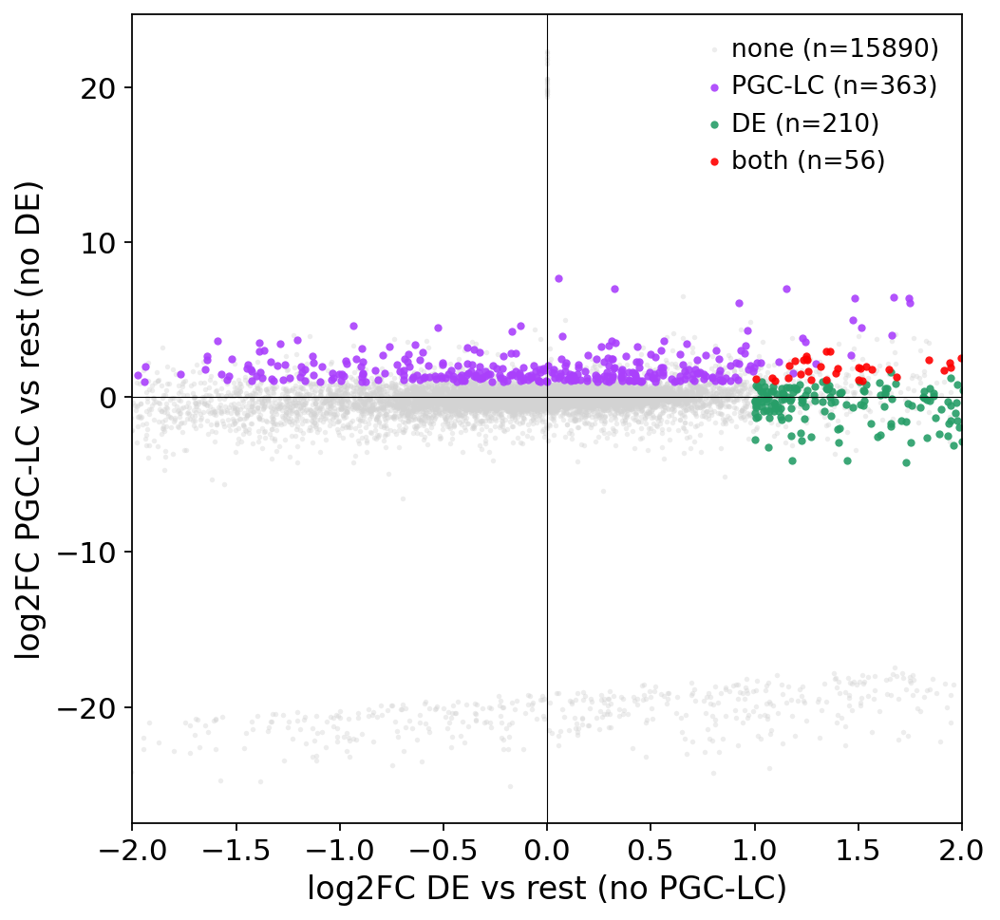

                             lfc_pgc       padj_pgc    lfc_de        padj_de  \
names                                                                          
S100Z (ENSG00000171643)     5.913114   1.143472e-11  6.269528   3.303215e-23   
SOX17 (ENSG00000164736)     4.862886  1.273774e-130  6.541202  1.767172e-275   
CRHBP (ENSG00000145708)     6.748512   5.358054e-55  4.420964   2.811316e-09   
PRDM1 (ENSG00000057657)     5.361428  5.217334e-113  5.192202  8.680773e-142   
SHISA3 (ENSG00000178343)    5.134584   1.077679e-22  4.272884   2.764243e-14   
CXCR4 (ENSG00000121966)     4.722793   1.516098e-70  3.576661   1.265268e-29   
FAM124B (ENSG00000124019)   3.898565   1.289148e-05  3.399975   2.538277e-04   
NOX4 (ENSG00000086991)      3.600133   8.401634e-07  3.342762   1.095907e-06   
COL23A1 (ENSG00000050767)   4.392007   1.115828e-80  2.446242   2.375691e-12   
NRCAM (ENSG00000091129)     4.288123   3.382760e-19  2.351955   1.901529e-02   
LEFTY1 (ENSG00000243709)    3.155794   1

In [150]:
# --- DE of PGC-LC and DE against the rest, excluding the other group each time ---
ad = adata.copy()
sc.pp.normalize_total(ad, target_sum=1e4)
sc.pp.log1p(ad)

PADJ = 0.05
LFC = 1.0  # log2 fold change threshold for calling a gene DE


def de_vs_rest(ad, group, exclude):
    sub = ad[ad.obs["leiden_sub"] != exclude].copy()
    sub.obs["test"] = np.where(sub.obs["leiden_sub"] == group, group, "rest")
    sub.obs["test"] = sub.obs["test"].astype("category")
    sc.tl.rank_genes_groups(
        sub, "test", groups=[group], reference="rest", method="wilcoxon"
    )
    df = sc.get.rank_genes_groups_df(sub, group=group).set_index("names")
    return df[["logfoldchanges", "pvals_adj"]]


pgc_df = de_vs_rest(ad, group="PGC-LC", exclude="DE")
de_df = de_vs_rest(ad, group="DE", exclude="PGC-LC")

genes = pgc_df.index.intersection(de_df.index)
res = pd.DataFrame(
    {
        "lfc_pgc": pgc_df.loc[genes, "logfoldchanges"],
        "padj_pgc": pgc_df.loc[genes, "pvals_adj"],
        "lfc_de": de_df.loc[genes, "logfoldchanges"],
        "padj_de": de_df.loc[genes, "pvals_adj"],
    }
)
# scanpy reports huge |lfc| for genes absent in one group; drop non-finite values
res = res.replace([np.inf, -np.inf], np.nan).dropna()

sig_pgc = (res["padj_pgc"] < PADJ) & (res["lfc_pgc"] > LFC)
sig_de = (res["padj_de"] < PADJ) & (res["lfc_de"] > LFC)
res["class"] = "none"
res.loc[sig_pgc, "class"] = "PGC-LC"
res.loc[sig_de, "class"] = "DE"
res.loc[sig_pgc & sig_de, "class"] = "both"
print(res["class"].value_counts())

# same colours as the UMAP
cat_to_color = dict(
    zip(adata.obs["leiden_sub"].cat.categories, adata.uns["leiden_sub_colors"])
)
class_color = {
    "none": "lightgrey",
    "PGC-LC": cat_to_color["PGC-LC"],
    "DE": cat_to_color["DE"],
    "both": "red",
}

fig, ax = plt.subplots(figsize=(7, 7))
for cls in ["none", "PGC-LC", "DE", "both"]:  # draw grey first, red last
    sub = res[res["class"] == cls]
    ax.scatter(
        sub["lfc_de"],
        sub["lfc_pgc"],
        s=6 if cls == "none" else 14,
        c=class_color[cls],
        alpha=0.4 if cls == "none" else 0.9,
        linewidths=0,
        label=f"{cls} (n={len(sub)})",
    )
ax.axhline(0, c="k", lw=0.5)
ax.axvline(0, c="k", lw=0.5)
ax.set_xlabel("log2FC DE vs rest (no PGC-LC)", fontsize=FONTSIZE)
ax.set_ylabel("log2FC PGC-LC vs rest (no DE)", fontsize=FONTSIZE)
ax.legend(frameon=False, fontsize=12)
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.grid(False)
plt.show()

# label the co-DE genes with the largest combined fold change
top_both = res[res["class"] == "both"].copy()
top_both["score"] = top_both["lfc_pgc"] + top_both["lfc_de"]
print(top_both.sort_values("score", ascending=False).head(30))

In [159]:
res.index

Index(['PDPN (ENSG00000162493)', 'IFI16 (ENSG00000163565)',
       'PRKAR2B (ENSG00000005249)', 'PLPP1 (ENSG00000067113)',
       'RAB15 (ENSG00000139998)', 'PLBD1 (ENSG00000121316)',
       'SOX17 (ENSG00000164736)', 'WASL (ENSG00000106299)',
       'ASRGL1 (ENSG00000162174)', 'LBH (ENSG00000213626)',
       ...
       'FABP5 (ENSG00000164687)', 'HEBP2 (ENSG00000051620)',
       'SPART (ENSG00000133104)', 'GJA1 (ENSG00000152661)',
       'SEPHS1 (ENSG00000086475)', 'DNMT3B (ENSG00000088305)',
       'TUBB2B (ENSG00000137285)', 'BCAT1 (ENSG00000060982)',
       'GSTO1 (ENSG00000148834)', 'TUBB2A (ENSG00000137267)'],
      dtype='object', name='names', length=16519)

                          symbol    lfc_de   lfc_pgc   class
names                                                       
SOX17 (ENSG00000164736)    SOX17  6.541202  4.862886    both
PRDM1 (ENSG00000057657)    PRDM1  5.192202  5.361428    both
TFAP2C (ENSG00000087510)  TFAP2C -1.589155  3.652997  PGC-LC
FOXA2 (ENSG00000125798)    FOXA2  4.513479 -0.419267      DE
OTX2 (ENSG00000165588)      OTX2  1.960450 -3.135696      DE
EOMES (ENSG00000163508)    EOMES  1.224723 -2.836290      DE


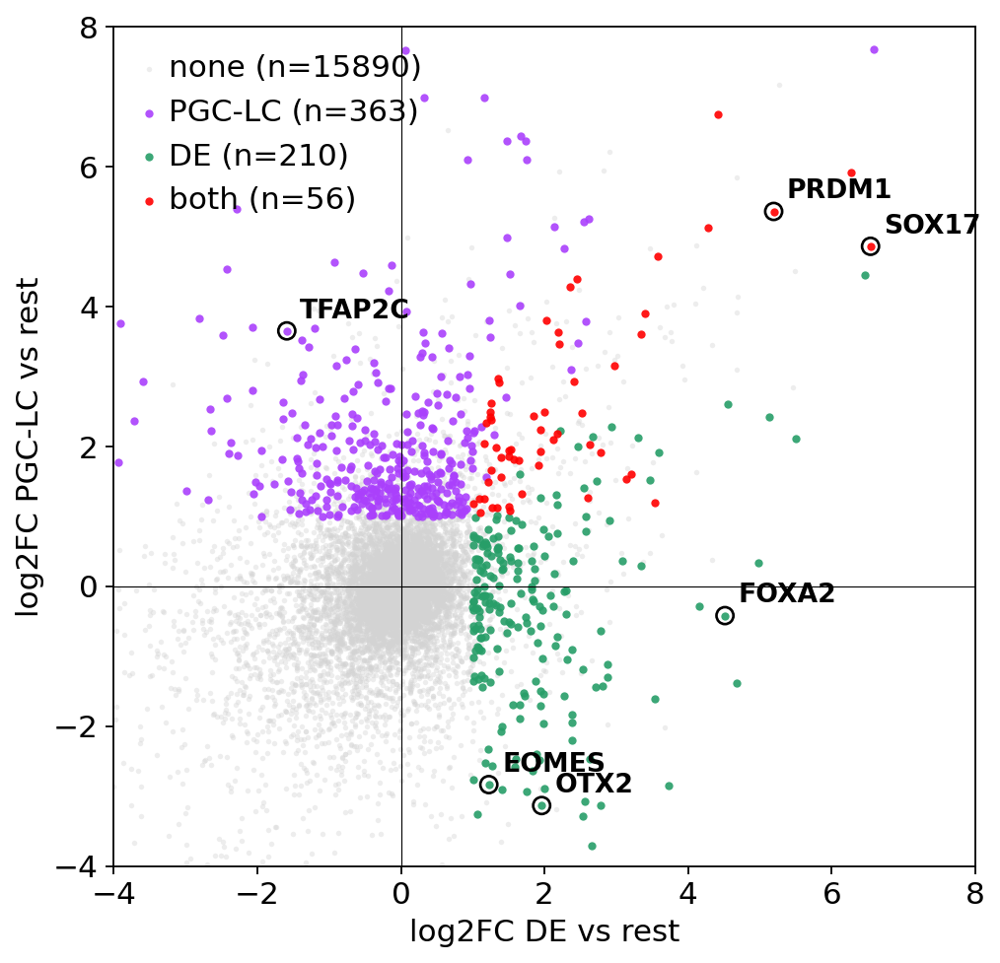

In [165]:
fig, ax = plt.subplots(figsize=(7, 7))
for cls in ["none", "PGC-LC", "DE", "both"]:  # draw grey first, red last
    sub = res[res["class"] == cls]
    ax.scatter(
        sub["lfc_de"],
        sub["lfc_pgc"],
        s=6 if cls == "none" else 14,
        c=class_color[cls],
        alpha=0.4 if cls == "none" else 0.9,
        linewidths=0,
        label=f"{cls} (n={len(sub)})",
    )
highlight = ["OTX2", "SOX17", "TFAP2C", "FOXA2", "PRDM1", "EOMES"]
symbols = res.index.str.split(" ").str[0]
hl = res[symbols.isin(highlight)].copy()
hl["symbol"] = hl.index.str.split(" ").str[0]
missing = sorted(set(highlight) - set(hl["symbol"]))
if missing:
    print("not in result table:", missing)
print(hl[["symbol", "lfc_de", "lfc_pgc", "class"]])

ax.scatter(
    hl["lfc_de"],
    hl["lfc_pgc"],
    s=60,
    facecolors="none",
    edgecolors="black",
    linewidths=1.2,
    zorder=5,
)
for _, row in hl.iterrows():
    ax.annotate(
        row["symbol"],
        (row["lfc_de"], row["lfc_pgc"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=12,
        fontweight="bold",
        zorder=6,
    )
ax.axhline(0, c="k", lw=0.5)
ax.axvline(0, c="k", lw=0.5)
ax.set_xlabel("log2FC DE vs rest", fontsize=14)
ax.set_ylabel("log2FC PGC-LC vs rest", fontsize=14)
ax.legend(frameon=False, fontsize=14)
ax.set_xlim(-4, 8)
ax.set_ylim(-4, 8)
ax.grid(False)
plt.show()

1526 TFs in result table


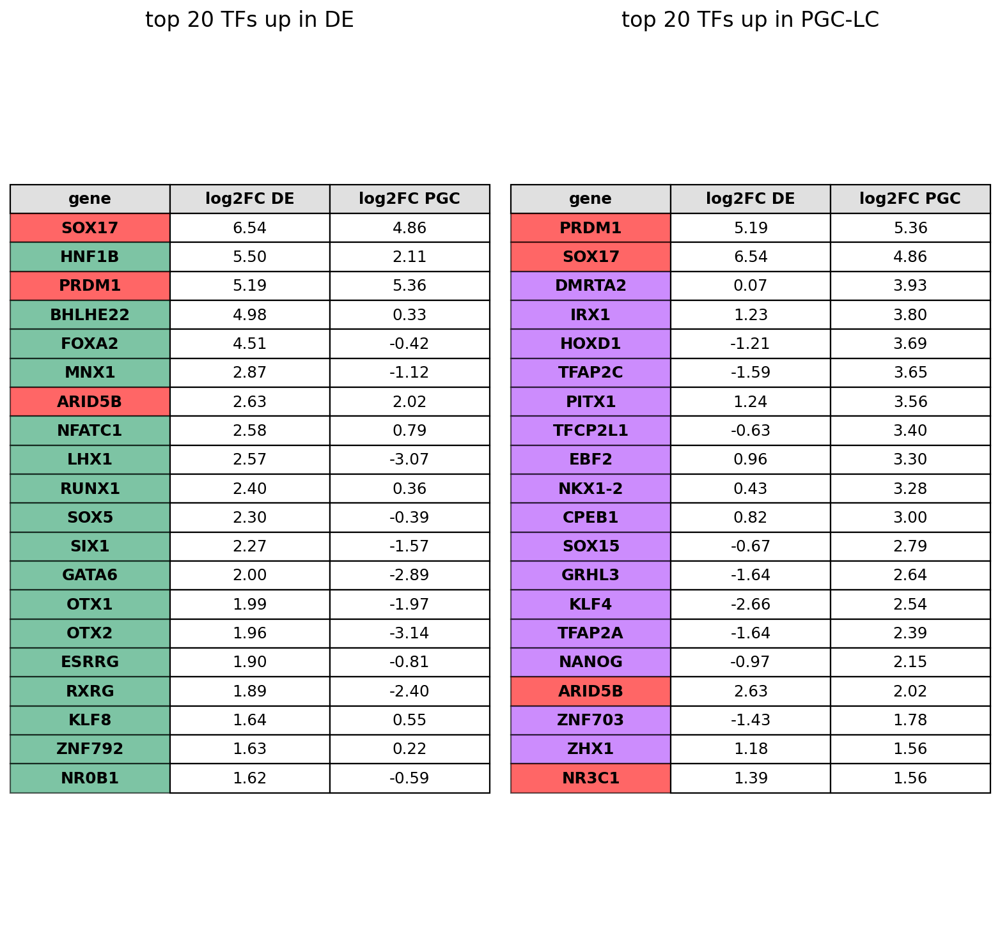

In [167]:
from pathlib import Path
import urllib.request

tf_url = "http://humantfs.ccbr.utoronto.ca/download/v_1.01/DatabaseExtract_v_1.01.csv"
tf_path = Path("human_tfs_lambert2018.csv")
if not tf_path.exists():
    urllib.request.urlretrieve(tf_url, tf_path)
tf_tab = pd.read_csv(tf_path, index_col=0)
tf_ids = set(tf_tab.loc[tf_tab["Is TF?"] == "Yes", "Ensembl ID"])

tab = res.copy()
tab["symbol"] = tab.index.str.split(" ").str[0]
tab["ensembl"] = tab.index.str.extract(r"\((ENSG\d+)\)")[0].values
tab = tab[tab["ensembl"].isin(tf_ids)]
print(f"{len(tab)} TFs in result table")

N_TOP = 20
top_de = (
    tab[tab["class"].isin(["DE", "both"])]
    .sort_values("lfc_de", ascending=False)
    .head(N_TOP)
)
top_pgc = (
    tab[tab["class"].isin(["PGC-LC", "both"])]
    .sort_values("lfc_pgc", ascending=False)
    .head(N_TOP)
)


def render_table(ax, df, title):
    cell_text = [
        [r["symbol"], f"{r['lfc_de']:.2f}", f"{r['lfc_pgc']:.2f}"]
        for _, r in df.iterrows()
    ]
    ax.axis("off")
    t = ax.table(
        cellText=cell_text,
        colLabels=["gene", "log2FC DE", "log2FC PGC"],
        loc="center",
        cellLoc="center",
    )
    t.auto_set_font_size(False)
    t.set_fontsize(11)
    t.scale(1, 1.4)
    for j in range(3):
        t[0, j].get_text().set_fontweight("bold")
        t[0, j].set_facecolor("#e0e0e0")
    # gene cell coloured by class: UMAP colour for single, red for co-upregulated
    for i, (_, r) in enumerate(df.iterrows(), start=1):
        t[i, 0].set_facecolor(class_color[r["class"]])
        t[i, 0].set_alpha(0.6)
        t[i, 0].get_text().set_fontweight("bold")
    ax.set_title(title, fontsize=FONTSIZE, pad=10)


fig, axes = plt.subplots(1, 2, figsize=(10, 0.4 * N_TOP + 1.5))
render_table(axes[0], top_de, f"top {N_TOP} TFs up in DE")
render_table(axes[1], top_pgc, f"top {N_TOP} TFs up in PGC-LC")
plt.tight_layout()
# plt.savefig("top_tf_table.png", dpi=300, bbox_inches="tight")
plt.show()

In [127]:
gas_reorder_ind

array([ 698, 3330,  223, ..., 2964,   43, 1926])

In [ ]:
gas_window_size = 20
gas_cell_types = pd.Categorical(adata.obs["leiden_sub"]).categories
gas_colors = adata.uns["leiden_sub_colors"]
gas_cell_composition_matrix = np.zeros((len(gas_cell_types) + 1, len(gas_cell_ids)))
for i, cell_type in enumerate(gas_cell_types):
    res = np.convolve(
        adata.obs.loc[gas_cell_ids, "leiden_sub"].iloc[gas_reorder_ind] == cell_type,
        np.ones(gas_window_size),
        mode="valid",
    )
    margin = int(np.ceil((gas_cell_composition_matrix.shape[1] - res.shape[0]) / 2))
    res = np.pad(res, (margin, margin), mode="constant")
    gas_cell_composition_matrix[i, :] = res[: gas_cell_composition_matrix.shape[1]]
gas_cell_composition_matrix[-1, :] = 1
gas_cell_composition_matrix = gas_cell_composition_matrix / np.sum(
    gas_cell_composition_matrix, axis=0
)

Clear bright patches can be observed between PGC and DE, suggesting that PGC and DE clades are not completely orthogonal